# Гибридная система рекомендаций книг с нейросетевым ранжировщиком

**Итоговый проект (сессионное задание) по курсу «Рекомендательные системы»**, МИФИ / Skillfactory, 3 семестр
**Автор:** Артём Власов (VLASOV) · **Данные:** Goodbooks-10k (версия с GitHub, 5 976 479 оценок)

**Цель:** на основе моделей из домашнего задания построить гибридную систему рекомендаций книг, которая
лучше отдельных моделей, учитывает тип пользователя, балансирует точность и разнообразие и включает
нейросетевую модель, а весь процесс от данных до рекомендаций запускается одной командой.

### Главные результаты (тест, 53 303 пользователя, K = 10)

| Система | Precision@10 | Recall@10 | nDCG@10 | Прирост nDCG@10 к лучшей модели ДЗ |
|---|---:|---:|---:|---:|
| Item-CF (explicit) — лучшая модель ДЗ | 0,085 | 0,057 | 0,094 | — |
| Взвешенный гибрид (классические модели) | 0,091 | 0,061 | 0,100 | +6% |
| GBDT-ранжировщик на расширенных признаках | 0,102 | 0,070 | 0,111 | +18% |
| Wide & Deep (нейросетевой ранжировщик) | **0,114** | **0,077** | **0,129** | **+37%** |
| **Итоговая система** (смесь W&D и гибрида + MMR) | 0,111 | 0,076 | 0,124 | +32% |

* Все приросты значимы: 95% бутстрэп-интервалы по пользователям не пересекают ноль (раздел 6).
* Итоговая система даёт самый разнообразный список среди всех моделей (ILD@10 = 0,640 против 0,555 у Item-CF).
* Для новых пользователей с 1 известным лайком итоговая система на 31% точнее популярности, тогда как
  Item-CF при такой истории почти бесполезен (nDCG@10 = 0,004).
* Весь пайплайн — от CSV до метрик — выполняется одной командой за ~13 минут на 2 ядрах CPU.
* **Раздел 9 — проверка гипотез из исследования.** Новые источники кандидатов (EASE, RP3beta, SASRec), признаки серий
  и LambdaMART подняли nDCG@10 до **0,183**: +47% к итоговой системе проекта и +94% к лучшей модели ДЗ.
  Покрытие каталога выросло с 50% до 70%.

### Архитектура решения

```
ratings.csv, books.csv, tags.csv, book_tags.csv
        │  1. Загрузка, очистка тегов, разбиение по времени внутри пользователя (как в ДЗ)
        ▼
Базовые модели из ДЗ ─ Popularity · Content (TF-IDF) · Item-CF implicit · Item-CF explicit · PureSVD
        │  2. Генерация кандидатов: топ-50 каждой модели → общий пул (~175 книг), прочитанное исключено
        ▼
Расширенные признаки ─ книги (популярность, разброс оценок, темы NMF…) · пользователи (активность,
        │               средняя оценка, «мейнстримность», разнообразие интересов…) · пары (скоры моделей,
        │               тематическое сходство, книги автора в истории…)
        ▼
Скоринг пула ─ взвешенный гибрид (веса по сегментам: новые / умеренные / активные)
        │       + нейросетевой ранжировщик Wide & Deep  →  смесь с долей α, подобранной по сегменту
        ▼
Балансировка ─ MMR: релевантность против схожести с уже выбранными книгами
        ▼
Топ-K рекомендаций → оценка: Precision@K, Recall@K, nDCG@K, покрытие, новизна, разнообразие
```

Весь код вынесен в пакет `src/recsys_pj` (см. README). Ноутбук вызывает шаги пайплайна по одному и
показывает промежуточные результаты; та же последовательность запускается из командной строки:
`python -m recsys_pj.pipeline --data-dir data --out-dir .`

### Что взято из домашнего задания и что добавлено

| Часть | Домашнее задание | Итоговый проект |
|---|---|---|
| Данные и разбиение | Последние 20% оценок пользователя — test, ещё 10% — validation; релевантно, если оценка ≥ 4 | Без изменений, чтобы числа были сравнимы |
| Метрики | Precision@K, Recall@K, nDCG@K (проверены на ручном примере) | Те же функции + покрытие, новизна, разнообразие списка (ILD), доля «длинного хвоста», бутстрэп-интервалы |
| Модели | Popularity, Content TF-IDF, Item-CF (explicit / implicit), SVD, PureSVD | Переиспользованы с гиперпараметрами из ДЗ, но приведены к общему интерфейсу `fit` / `score(users, history)` |
| Гибрид | Один вес CF, линейно растущий с длиной истории | Пул кандидатов от всех моделей, веса по сегментам, MMR, нейросетевой ранжировщик |
| Признаки | Только скоры моделей | 10 признаков книг, 7 признаков пользователя, 15 признаков пары |

SVD из `surprise` в гибрид не включён: в ДЗ его прямой топ-N оказался близок к случайному (nDCG@10 = 0,002),
а матричное разложение в системе представляет PureSVD.

## 1. Окружение и настройки

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

sys.path.insert(0, str(Path("src").resolve()))
from recsys_pj import Config, Pipeline
from recsys_pj import plots
from recsys_pj.hybrid import segment_of

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

cfg = Config()          # все параметры — в src/recsys_pj/config.py
FIG = cfg.figures_dir
pipe = Pipeline(cfg)
started_all = time.perf_counter()
pd.Series({k: v for k, v in cfg.to_dict().items()
           if k in ("seed", "relevance_threshold", "test_fraction", "val_fraction", "k_values",
                    "itemcf_implicit_k", "itemcf_explicit_k", "puresvd_factors", "n_topics",
                    "candidates_per_model", "segment_new_max", "segment_active_min", "tune_users",
                    "ranker_train_users", "wd_embedding_dim", "wd_hidden", "wd_loss")}, name="Значение").to_frame()

,Значение
seed,42
relevance_threshold,4
test_fraction,0.2
val_fraction,0.125
k_values,"(5, 10, 20)"
itemcf_implicit_k,5
itemcf_explicit_k,10
puresvd_factors,400
n_topics,20
candidates_per_model,50


## 2. Загрузка и предобработка данных

Шаг `load` скачивает CSV, если их нет в `data/`, переводит `goodreads_book_id` тегов в `book_id` оценок
и удаляет служебные теги-«полки» (`to-read`, `owned` и т. п. — около 80% присвоений, см. ДЗ).
Шаг `preprocess` делает то же разбиение по времени, что и в ДЗ, строит TF-IDF профили книг,
тематические категории и контентные эмбеддинги для оценки разнообразия.

In [2]:
pipe.load().preprocess()
display(pipe.results["split"].round(3))
sp_ = pipe.splits
print(f"Пользователей: {sp_.idx.n_users:,}, книг: {sp_.idx.n_items:,}; "
      f"пользователей с релевантными книгами в тесте: {(sp_.Y_test.getnnz(axis=1) > 0).sum():,}")

▶ 1. Загрузка данных


  оценок: 5,976,479, книг: 10,000
  готово за 3 с
▶ 2. Предобработка: разбиение, TF-IDF, темы


  готово за 5 с


,Оценок,Доля,Доля релевантных
train_fit,4143355,0.693,0.694
validation,616404,0.103,0.674
test,1216720,0.204,0.683


Пользователей: 53,424, книг: 10,000; пользователей с релевантными книгами в тесте: 53,303


## 3. Этап 1. Расширенные признаки

### 3.1. Тематические категории книг

Теги — лучший источник тем, но их ~34 тыс. Чтобы получить компактные категории, к матрице
«книга × содержательный тег» (TF-IDF от log-частоты присвоений, до 30 тегов на книгу) применено
неотрицательное матричное разложение NMF с 20 компонентами. Каждая книга получает распределение по темам,
тема названа тремя самыми весомыми тегами.

,Тема (3 главных тега),Книг с этой главной темой
0,mystery / crime / mysteries,905
1,paranormal / urban-fantasy / paranormal-romance,725
2,classics / classic / literature,725
3,memoir / biography / non-fiction,708
4,middle-grade / childrens / children,695
5,literary-fiction / contemporary-fiction / gene...,687
6,historical-fiction / historical / history,646
7,high-fantasy / epic-fantasy / fantasy,510
8,self-help / non-fiction / business,489
9,chick-lit / chicklit / chic-lit,454


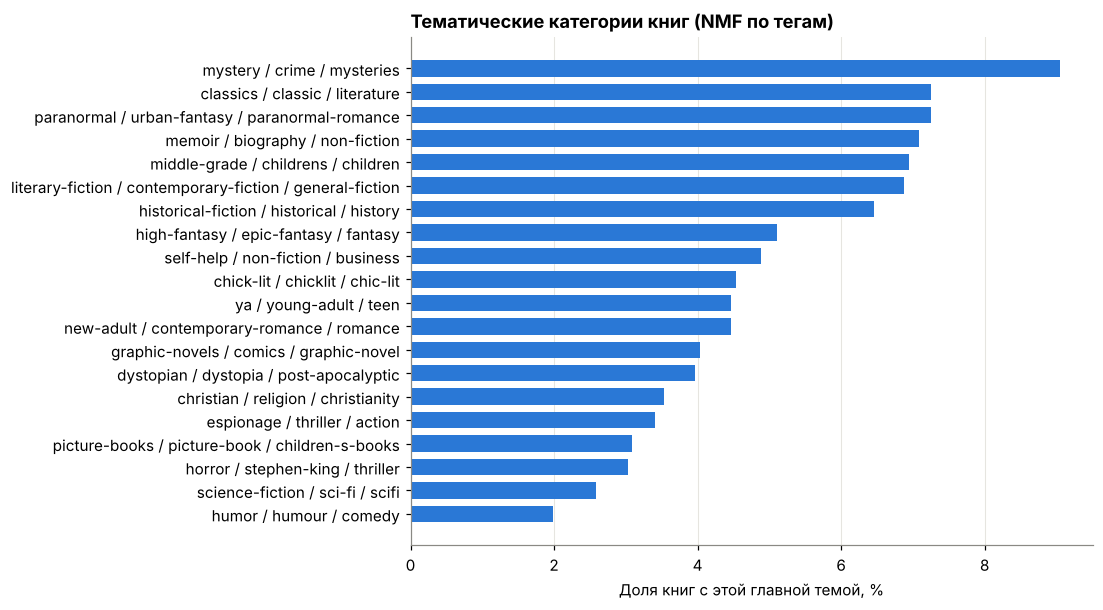

In [3]:
topics = pipe.topics
topic_table = pd.DataFrame({"Тема (3 главных тега)": topics.names,
                            "Книг с этой главной темой": np.bincount(topics.item_topics.argmax(1), minlength=topics.n_topics)})
display(topic_table.sort_values("Книг с этой главной темой", ascending=False).reset_index(drop=True))
plots.topics(topics.names, topics.item_topics, FIG);

Темы содержательны и узнаваемы: отдельные компоненты выделяют фэнтези, классику, детективы, романтику,
нон-фикшн, young adult и т. д. Это даёт признаки «главная тема книги» и «тематический профиль
пользователя», а также пересечение «тема пользователя × тема книги» для Wide-части нейросети.

### 3.2. Признаки книг, пользователей и взаимодействий

Признаки книг считаются по обучающей истории (на этапе подбора — `train_fit`, на тесте — `train_full`),
признаки пользователя и пары — по переданной истории пользователя. Поэтому одни и те же функции работают
для полных и укороченных историй и для совершенно нового пользователя.

In [4]:
pipe.fit_base()
gen = pipe.gen_fit
builder = gen.builder

feature_doc = pd.DataFrame([
    ("Книга", "item_log_ratings, item_log_likes", "Популярность: log(1 + число оценок / лайков)"),
    ("Книга", "item_like_share", "Доля оценок ≥ 4"),
    ("Книга", "item_mean_rating", "Средняя оценка, сглаженная к глобальной (m = 20)"),
    ("Книга", "item_std_rating, item_rating_entropy", "Разнообразие оценок: стандартное отклонение и энтропия распределения 1–5"),
    ("Книга", "item_goodreads_avg, item_goodreads_log_count", "Метаданные каталога (books.csv)"),
    ("Книга", "item_year", "Год первой публикации"),
    ("Книга", "item_topic_focus + главная тема", "Насколько книга сосредоточена в одной теме"),
    ("Пользователь", "user_log_ratings, user_log_likes, user_like_share", "Активность и доля лайков"),
    ("Пользователь", "user_mean_rating, user_std_rating", "Средняя оценка и её разброс («строгость»)"),
    ("Пользователь", "user_mainstream", "Средняя популярность прочитанных книг"),
    ("Пользователь", "user_topic_entropy + главная тема", "Разнообразие интересов по темам"),
    ("Пара", "score::*, z::* (5 + 5)", "Скоры всех базовых моделей и их z-оценки в списке пользователя"),
    ("Пара", "topic_affinity", "Схожесть темы книги с тематическим профилем пользователя"),
    ("Пара", "author_likes", "Сколько книг этого автора пользователю понравилось"),
    ("Пара", "mean_diff, pop_diff", "Средняя оценка книги минус средняя оценка пользователя; популярность книги минус «мейнстримность» пользователя"),
    ("Пара", "n_sources", "Сколько моделей поставили книгу в свой топ-50"),
], columns=["Уровень", "Признаки", "Смысл"])
display(feature_doc)
print(f"Всего признаков на пару «пользователь — книга»: {len(gen.feature_names)}")
display(builder.item_frame.describe().T[["mean", "std", "min", "50%", "max"]].round(3))

▶ 3.1. Базовые модели на train_fit


  готово за 25 с


,Уровень,Признаки,Смысл
0,Книга,"item_log_ratings, item_log_likes",Популярность: log(1 + число оценок / лайков)
1,Книга,item_like_share,Доля оценок ≥ 4
2,Книга,item_mean_rating,"Средняя оценка, сглаженная к глобальной (m = 20)"
3,Книга,"item_std_rating, item_rating_entropy",Разнообразие оценок: стандартное отклонение и ...
4,Книга,"item_goodreads_avg, item_goodreads_log_count",Метаданные каталога (books.csv)
5,Книга,item_year,Год первой публикации
6,Книга,item_topic_focus + главная тема,Насколько книга сосредоточена в одной теме
7,Пользователь,"user_log_ratings, user_log_likes, user_like_share",Активность и доля лайков
8,Пользователь,"user_mean_rating, user_std_rating",Средняя оценка и её разброс («строгость»)
9,Пользователь,user_mainstream,Средняя популярность прочитанных книг


Всего признаков на пару «пользователь — книга»: 32


,mean,std,min,50%,max
item_log_ratings,5.251,1.078,0.693,5.069,9.874
item_log_likes,4.859,1.100,0.000,4.700,9.703
item_like_share,0.685,0.123,0.000,0.698,1.000
item_mean_rating,3.916,0.254,2.206,3.934,4.798
item_std_rating,0.928,0.119,0.000,0.924,1.574
item_rating_entropy,1.795,0.196,-0.000,1.811,2.301
item_goodreads_avg,4.002,0.254,2.470,4.020,4.820
item_goodreads_log_count,10.185,0.937,7.907,9.960,15.380
item_year,-0.417,1.823,-10.000,0.200,0.850
item_topic_focus,0.627,0.200,0.167,0.608,1.000


In [5]:
example_users = np.array([1, 2, 3, 100, 1000])
user_frame, profile, n_likes = builder.user_features(example_users, sp_.hist_fit)
example = user_frame.assign(user_id=sp_.idx.user_ids[example_users],
                            главная_тема=[topics.names[t] for t in profile.argmax(1)]).set_index("user_id")
display(example.round(3))

,user_log_ratings,user_log_likes,user_like_share,user_mean_rating,user_std_rating,user_mainstream,user_topic_entropy,главная_тема
user_id,,,,,,,,
2,3.829,3.638,0.822,4.333,0.869,6.593,2.647,self-help / non-fiction / business
3,4.159,0.693,0.016,1.651,0.820,6.533,1.786,literary-fiction / contemporary-fiction / gene...
4,4.543,4.220,0.720,3.914,0.799,8.043,3.717,classics / classic / literature
101,4.382,4.094,0.747,4.051,0.913,7.378,3.568,literary-fiction / contemporary-fiction / gene...
1001,4.205,3.664,0.576,3.591,0.674,6.954,3.294,classics / classic / literature


## 4. Этап 2. Гибридная система

### 4.1. Генерация кандидатов

Каждая из пяти базовых моделей отдаёт свой топ-50 непрочитанных книг; списки объединяются в общий пул
без повторов. Уже оценённые пользователем книги исключаются на этом шаге (скор = −∞), поэтому дальше
ни один скорер не может их вернуть, — это дополнительно проверяется `assert` при оценке на тесте.
Пул решает две задачи: даёт ранжировщику кандидатов из разных источников (популярное, похожее по
содержанию, коллаборативное) и ограничивает дорогие вычисления ~175 книгами вместо 10 000.

In [6]:
pipe.build_tuning()
tuning = pipe.tuning
natural = tuning.subset(tuning.tag == "full")
pool_size = natural.valid.sum(axis=1)
pool_recall = natural.labels.sum(axis=1) / natural.n_relevant
print(f"Размер пула: в среднем {pool_size.mean():.0f} книг (от {pool_size.min()} до {pool_size.max()})")
print(f"Доля релевантных книг validation, попавших в пул: {pool_recall.mean():.1%}")
# Вклад источников: какая доля релевантных книг пула пришла бы из каждой модели в одиночку
contrib = {}
for m, name in enumerate(gen.model_names):
    in_top = natural.z[:, :, m] >= np.sort(np.where(natural.valid, natural.z[:, :, m], -np.inf), axis=1)[:, -cfg.candidates_per_model][:, None]
    contrib[name] = ((natural.labels & in_top).sum() / natural.labels.sum())
display(pd.Series(contrib, name="Доля релевантных книг пула, которые есть в топ-50 модели").round(3).to_frame())

▶ 3.2. Пул кандидатов и признаки для validation


  пользователей для подбора: 6,000; доля релевантных книг validation внутри пула: 41.6%; средний размер пула: 176
  готово за 26 с
Размер пула: в среднем 176 книг (от 100 до 237)
Доля релевантных книг validation, попавших в пул: 41.6%


,"Доля релевантных книг пула, которые есть в топ-50 модели"
Popularity,0.247
Content (TF-IDF),0.277
Item-CF (implicit),0.521
Item-CF (explicit),0.483
PureSVD,0.424


Ни одна модель в одиночку не покрывает весь пул релевантных книг: объединение источников действительно
расширяет набор кандидатов. Верхняя граница качества любой системы на этом пуле — доля релевантных книг
внутри него (на тесте она приведена в разделе 6).

### 4.2. Взвешенный гибрид и сегменты пользователей

Скор книги — взвешенная сумма z-оценок базовых моделей: $s_{ui} = \sum_m w_m(\text{сегмент}_u)\, z_{m,ui}$.
z-оценка внутри списка пользователя приводит модели к общей шкале. Пользователи делятся на три типа по
числу лайков в истории: **новые** (≤ 10), **умеренные** (11–50) и **активные** (> 50).

Естественных новичков в Goodbooks-10k почти нет (минимум 19 оценок у пользователя), поэтому сегмент
«новые» моделируется: у половины пользователей подбора история обрезается до первых 1, 3, 5 и 10 лайков.
Веса ищутся случайным поиском по симплексу (распределение Дирихле) с локальным уточнением, критерий —
nDCG@10 на validation. Чтобы не переобучиться на шум, свои веса сегмента используются, только если они
лучше общих хотя бы на 1%.

▶ 3.3. Подбор весов гибрида (общих и по сегментам)


              Сегмент  nDCG@10 общих весов  nDCG@10 весов сегмента Используются
0  Новые (≤10 лайков)               0.0175                  0.0227         свои
1   Умеренные (11–50)               0.0839                  0.0848         свои
2      Активные (>50)               0.0827                  0.0832        общие
                    Popularity  Content (TF-IDF)  Item-CF (implicit)  Item-CF (explicit)  PureSVD
Новые (≤10 лайков)       0.841             0.073               0.000               0.086    0.000
Умеренные (11–50)        0.039             0.273               0.149               0.235    0.304
Активные (>50)           0.137             0.127               0.159               0.279    0.299
Все (общие веса)         0.137             0.127               0.159               0.279    0.299
  готово за 50 с


,Сегмент,nDCG@10 общих весов,nDCG@10 весов сегмента,Используются
0,Новые (≤10 лайков),0.0175,0.0227,свои
1,Умеренные (11–50),0.0839,0.0848,свои
2,Активные (>50),0.0827,0.0832,общие


,Popularity,Content (TF-IDF),Item-CF (implicit),Item-CF (explicit),PureSVD
Новые (≤10 лайков),0.841,0.073,0.000,0.086,0.000
Умеренные (11–50),0.039,0.273,0.149,0.235,0.304
Активные (>50),0.137,0.127,0.159,0.279,0.299
Все (общие веса),0.137,0.127,0.159,0.279,0.299


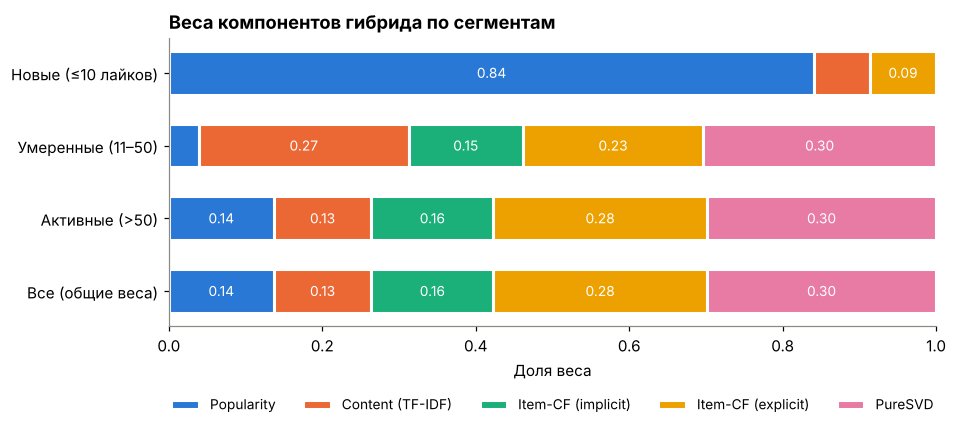

In [7]:
pipe.tune_hybrid()
display(pipe.results["segment_weight_gain"].round(4))
display(pipe.results["hybrid_weights"].round(3))
plots.hybrid_weights(pipe.results["hybrid_weights"], FIG);

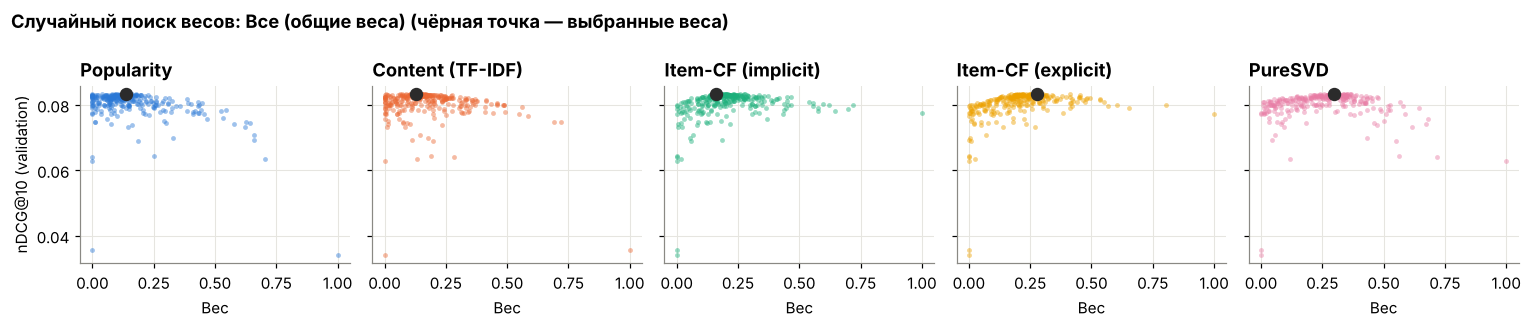

In [8]:
plots.weight_search(pipe.results["weight_search"], gen.model_names, "Все (общие веса)", FIG);

**Что показали веса.**

* **Общие веса** распределены между всеми пятью моделями: больше всего у PureSVD (0,30) и Item-CF explicit (0,28),
  но и популярность (0,14), и контентная модель (0,13) получают заметный вес. Это значит, что модели
  дополняют друг друга, а не дублируют: даже слабая в одиночку контентная модель (nDCG@10 = 0,048)
  полезна как поправка.
* **Новые пользователи** получают совсем другой рецепт: 84% веса — популярность, остальное — контент и
  Item-CF explicit; implicit CF и PureSVD обнулены. При 1–10 лайках коллаборативный сигнал слишком шумный,
  и безопаснее показывать проверенные бестселлеры. Свои веса дают здесь +30% nDCG@10 к общим (0,0227 против 0,0175).
* **Умеренные пользователи** почти не отличаются от общих (+1,1%), а для **активных** выигрыш меньше порога в 1%, и
  для них оставлены общие веса. Сегментация весов важна прежде всего для холодного старта.
* График случайного поиска показывает пологий максимум: в широком диапазоне весов nDCG@10 меняется слабо,
  а резко падает лишь на краях симплекса (одна модель с весом около 1). Значит, выбранные веса устойчивы,
  а гибрид не зависит от точной настройки.

## 5. Продвинутая часть: нейросетевой ранжировщик Wide & Deep

### 5.1. Постановка и данные

Выбран **нейросетевой ранжировщик архитектуры Wide & Deep** (вариант 1b/1c задания): он переупорядочивает пул
кандидатов, используя все расширенные признаки. Схема обучения стандартна для двухэтапных систем:

* признаки считаются по истории `train_fit`, метка — понравилась ли книга пользователю в периоде validation;
* обучающая выборка — 20 000 пользователей, не пересекающихся с пользователями подбора весов; для 25% из них
  добавлена ещё и укороченная до 1–10 лайков версия истории (всего 25 000 историй), чтобы модель умела работать с новичками;
* ранняя остановка — по nDCG@10 на пользователях подбора;
* на тесте тот же ранжировщик применяется к признакам, посчитанным по `train_full`.

**Архитектура.**
* *Wide* (запоминание): линейная часть по плотным признакам + обучаемые веса пересечений
  «тема пользователя × тема книги» (20 × 20), «активность пользователя × популярность книги» (6 × 10)
  и собственный вес каждой книги.
* *Deep* (обобщение): эмбеддинг книги-кандидата (32), эмбеддинг пользователя как **среднее эмбеддингов
  понравившихся ему книг** (EmbeddingBag) — поэтому модель применима к новым пользователям без
  переобучения, — их поэлементное произведение, эмбеддинг темы и плотные признаки → MLP 128 → 64 → 1.
* Выход: $\sigma(y_{wide} + y_{deep})$.

**Функция потерь.** Поточечная BCE в пробном прогоне уступала GBDT: при 1,6% положительных строк её
доминируют пользователи с большим числом релевантных книг. Поэтому используется списочная
softmax-кросс-энтропия внутри пула каждого пользователя (ListNet) плюс 0,1·BCE: каждый пользователь
вносит одинаковый вклад, что ближе к усреднённому nDCG.

In [9]:
pipe.build_ranker_data()
td = pipe.train_data
print(f"Строк для обучения: {len(td.labels):,}; историй: {td.n_users:,}; доля положительных: {td.labels.mean():.2%}")
print(f"Плотных признаков: {td.features.shape[1]}")

▶ 3.4. Данные для ранжировщиков


  строк для обучения: 4,497,900 (25,000 историй), доля положительных: 1.57%
  готово за 40 с
Строк для обучения: 4,497,900; историй: 25,000; доля положительных: 1.57%
Плотных признаков: 32


▶ 3.5. Обучение Wide & Deep


  [Wide & Deep] эпоха 1: loss=4.9757, val nDCG@10=0.0538 (24 с)


  [Wide & Deep] эпоха 2: loss=4.7923, val nDCG@10=0.0539 (23 с)


  [Wide & Deep] эпоха 3: loss=4.7232, val nDCG@10=0.0535 (24 с)


  [Wide & Deep] эпоха 4: loss=4.6600, val nDCG@10=0.0537 (24 с)
  готово за 97 с


,эпоха,loss,val nDCG@10,"время, с"
0,1,4.9757,0.0538,23.6302
1,2,4.7923,0.0539,22.9719
2,3,4.7232,0.0535,23.7753
3,4,4.6600,0.0537,24.0836


Параметров в сети: 676,574


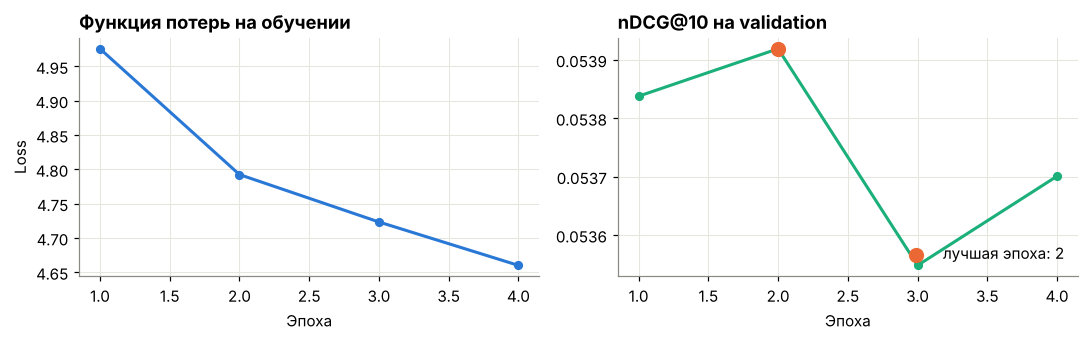

In [10]:
pipe.train_neural()
wd_history = pipe.results["wd_history"]
display(wd_history.round(4))
n_params = sum(p.numel() for p in pipe.wd.net.parameters())
print(f"Параметров в сети: {n_params:,}")
plots.training_curves(wd_history, FIG);

### 5.2. Сравнение с классическим ранжировщиком и абляции

Для честного сравнения нейросетевого подхода с классическим на **тех же кандидатах и признаках** обучен
градиентный бустинг (`HistGradientBoostingClassifier`, вес строки 1/число релевантных у пользователя).
Абляции показывают вклад частей сети и расширенных признаков. Все значения — nDCG@10 на validation
(пользователи подбора), тест в выборе не участвует.

▶ 3.6. Классический ранжировщик и абляции


                                      Вариант  nDCG@10 (полные истории)  nDCG@10 (укороченные истории)
0                                 Wide & Deep                    0.0943                         0.0337
1  Только Wide (линейная часть + пересечения)                    0.0894                         0.0259
2              Только Deep (эмбеддинги + MLP)                    0.0961                         0.0343
3                         GBDT (все признаки)                    0.0886                         0.0285
4         GBDT (только скоры базовых моделей)                    0.0782                         0.0202


  готово за 162 с


,Вариант,nDCG@10 (полные истории),nDCG@10 (укороченные истории)
0,Wide & Deep,0.0943,0.0337
1,Только Wide (линейная часть + пересечения),0.0894,0.0259
2,Только Deep (эмбеддинги + MLP),0.0961,0.0343
3,GBDT (все признаки),0.0886,0.0285
4,GBDT (только скоры базовых моделей),0.0782,0.0202


,Группа признаков,nDCG@10 после перемешивания,Падение nDCG@10
0,Скоры базовых моделей,0.0374,0.0568
1,Признаки книг,0.0750,0.0192
4,Книги автора в истории,0.0912,0.0031
2,Признаки пользователя,0.0913,0.0030
5,"Отклонения от профиля (оценка, популярность)",0.0925,0.0018
3,Тематическое сходство с историей,0.0937,0.0006
6,Число моделей-источников,0.0948,-0.0005


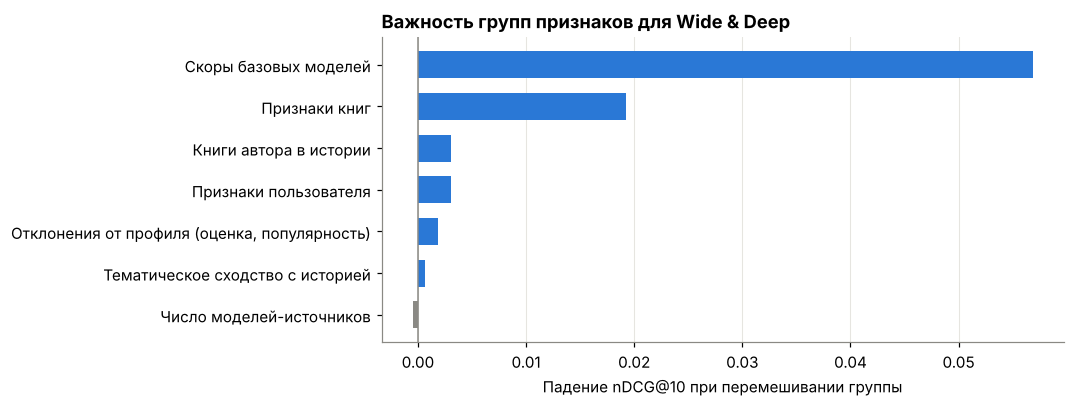

In [11]:
pipe.train_baselines()
display(pipe.results["ranker_ablation"].round(4))
display(pipe.results["feature_importance"].round(4))
plots.feature_importance(pipe.results["feature_importance"], FIG);

**Выводы по абляциям и признакам.**

* **Нейросетевой ранжировщик лучше классического** на тех же кандидатах и признаках: 0,0943 против 0,0886 у GBDT
  (+6%) на полных историях и 0,0337 против 0,0285 (+18%) на укороченных. Основной вклад даёт Deep-часть:
  эмбеддинг пользователя как среднее эмбеддингов его книг переносит знания между похожими книгами и
  работает даже при одном лайке.
* **Wide-часть в одиночку слабее** (0,0894), а Deep-часть в одиночку даже чуть лучше полной модели (0,0961).
  Запоминание пар «тема × тема» и «активность × популярность» в этой задаче почти ничего не добавляет к
  тому, что уже видит MLP: признаков немного, и все они плотные. Wide & Deep оставлен как архитектура,
  указанная в задании, но в выводах это отмечено как кандидат на упрощение.
* **Расширенные признаки полезны:** GBDT на одних скорах базовых моделей даёт 0,0782, а со всеми признаками — 0,0886
  (+13%). По важности первыми идут скоры базовых моделей (это ядро гибрида), затем признаки книг
  (популярность, средняя оценка и разброс оценок). Признаки «книги автора в истории» и «признаки пользователя»
  дают заметный, но небольшой вклад, а тематическое сходство и число моделей-источников почти дублируют
  информацию, которая уже есть в скорах.
* Обучение сходится быстро: лучший результат на validation достигается на 2-й эпохе, после чего срабатывает
  ранняя остановка. В сети 676 тыс. параметров, основная часть — эмбеддинги книг.

### 5.3. Интеграция в гибридную систему и балансировка

Нейросеть не заменяет гибрид, а встраивается в него: итоговый скор —
$\alpha_s \cdot z(\text{W\&D}) + (1-\alpha_s)\cdot z(\text{взвешенный гибрид})$, где доля $\alpha_s$ подбирается
на validation отдельно для каждого сегмента. Затем список балансируется методом **MMR**
(Maximal Marginal Relevance): книга выбирается по $\lambda \cdot \text{релевантность} - (1-\lambda)\cdot
\max_{j \in S} \cos(e_i, e_j)$, где $S$ — уже выбранные книги, $e$ — контентные эмбеддинги. Берётся
наименьшее $\lambda$, при котором nDCG@10 на validation падает не более чем на 2%.

▶ 3.7. Смесь Wide & Deep с гибридом по сегментам и порог MMR


                       0.0     0.1     0.2     0.3     0.4     0.5     0.6     0.7     0.8     0.9     1.0  GBDT (для сравнения)  Выбрано α
Новые (≤10 лайков)  0.0227  0.0241  0.0254  0.0267  0.0283  0.0297  0.0310  0.0323  0.0335  0.0340  0.0340                0.0287        1.0
Умеренные (11–50)   0.0848  0.0858  0.0873  0.0882  0.0894  0.0915  0.0943  0.0971  0.0996  0.0993  0.0950                0.0882        0.8
Активные (>50)      0.0827  0.0833  0.0843  0.0850  0.0863  0.0878  0.0904  0.0929  0.0954  0.0965  0.0935                0.0890        0.9


  выбран λ = 0.85 (потеря nDCG@10 не более 2%)
  готово за 22 с


,0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0,GBDT (для сравнения),Выбрано α
Новые (≤10 лайков),0.0227,0.0241,0.0254,0.0267,0.0283,0.0297,0.0310,0.0323,0.0335,0.0340,0.0340,0.0287,1.0
Умеренные (11–50),0.0848,0.0858,0.0873,0.0882,0.0894,0.0915,0.0943,0.0971,0.0996,0.0993,0.0950,0.0882,0.8
Активные (>50),0.0827,0.0833,0.0843,0.0850,0.0863,0.0878,0.0904,0.0929,0.0954,0.0965,0.0935,0.0890,0.9


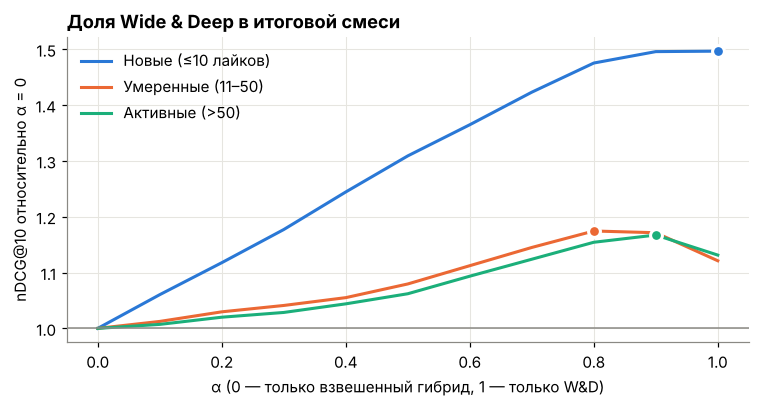

In [12]:
pipe.tune_blend()
alpha = pipe.results["alpha_choice"]
display(alpha.round(4))
plots.alpha_blend(alpha.drop(columns=["GBDT (для сравнения)", "Выбрано α"]), FIG);

,λ,Precision@10,Recall@10,nDCG@10,Coverage@10,Novelty@10,ILD@10,LongTail@10
0,1.00,0.0737,0.0978,0.0979,0.3809,11.1732,0.5898,0.3026
1,0.95,0.0735,0.0974,0.0975,0.3795,11.1542,0.6036,0.2987
2,0.90,0.0730,0.0972,0.0969,0.3784,11.1343,0.6186,0.2946
3,0.85,0.0727,0.0970,0.0966,0.3752,11.1055,0.6352,0.2888
4,0.80,0.0720,0.0961,0.0956,0.3738,11.0723,0.6529,0.2818
5,0.70,0.0697,0.0930,0.0927,0.3697,10.9926,0.6927,0.2664
6,0.60,0.0649,0.0875,0.0876,0.3614,10.8759,0.7391,0.2433
7,0.50,0.0576,0.0781,0.0804,0.3532,10.7403,0.7858,0.2190


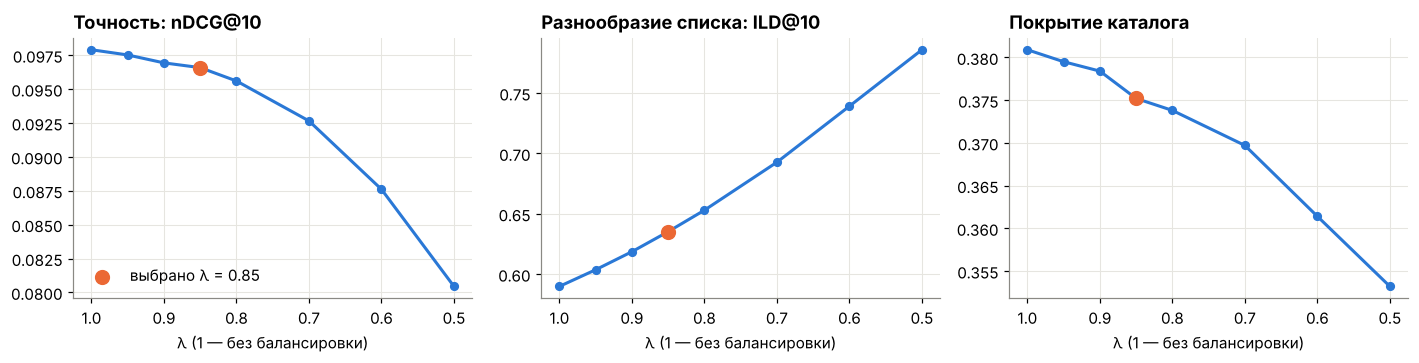

In [13]:
mmr = pipe.results["mmr_tradeoff_val"]
display(mmr.round(4))
plots.mmr_tradeoff(mmr, pipe.router.mmr_lambda, FIG);

**Интеграция и балансировка.**

* На validation смесь лучше обеих частей по отдельности: для умеренных и активных оптимальная доля нейросети —
  α = 0,8 и 0,9 (+17% nDCG@10 к чистому взвешенному гибриду и +3–5% к чистой W&D), для новых — α = 1.
  Классический гибрид добавляет устойчивость там, где нейросеть ошибается, а нейросеть исправляет порядок
  внутри пула.
* MMR даёт плавный компромисс: при λ = 0,85 nDCG@10 на validation снижается на 1,3%, а разнообразие списка
  (ILD@10) растёт на 7,7%. При λ ≤ 0,7 потери точности становятся заметными (−5% и больше), поэтому глубже
  балансировать не стоит. Покрытие каталога при этом немного падает: MMR разнообразит
  **каждый список**, но чаще выбирает «типичных представителей» тем, а не редкие книги.

## 6. Этап 3. Оценка на тесте

Базовые модели переобучаются на полном train (`train_full`), веса, доли α и ранжировщик берутся из
этапа подбора. Все системы оцениваются на одних и тех же 53 303 пользователях с релевантными книгами в тесте.

In [14]:
pipe.refit_stage().evaluate_stage()
metrics = pipe.results["metrics_test"]
print(f"Доля релевантных книг теста внутри пула кандидатов: {pipe.results['pool_recall_test'].iloc[0, 0]:.1%}")
display(metrics.round(4))

▶ 4. Переобучение базовых моделей на train_full


  готово за 26 с
▶ 5.1. Рекомендации и метрики на тесте


  [тест] доля релевантных книг внутри пула кандидатов: 34.5%


  готово за 131 с
▶ 5.2. Новые пользователи (симуляция укороченной истории на тесте)


  [n=1] доля релевантных книг внутри пула кандидатов: 13.1%


  [n=3] доля релевантных книг внутри пула кандидатов: 15.2%


  [n=5] доля релевантных книг внутри пула кандидатов: 16.5%


  [n=10] доля релевантных книг внутри пула кандидатов: 19.0%


  готово за 48 с
Доля релевантных книг теста внутри пула кандидатов: 34.5%


,Precision@5,Recall@5,nDCG@5,Precision@10,Recall@10,nDCG@10,Precision@20,Recall@20,nDCG@20,Coverage@10,Novelty@10,ILD@10,LongTail@10
Модель,,,,,,,,,,,,,
Popularity,0.0502,0.0165,0.0518,0.0413,0.0268,0.0458,0.0336,0.0441,0.0456,0.0060,8.1452,0.4717,0.0000
Content (TF-IDF),0.0488,0.0173,0.0504,0.0444,0.0307,0.0481,0.0382,0.0518,0.0506,0.6387,12.8131,0.2805,0.5887
Item-CF (implicit),0.0941,0.0323,0.0987,0.0812,0.0550,0.0902,0.0687,0.0920,0.0929,0.5669,10.9022,0.6106,0.2715
Item-CF (explicit),0.0984,0.0331,0.1031,0.0851,0.0567,0.0942,0.0695,0.0917,0.0946,0.6554,11.1729,0.5546,0.3349
PureSVD,0.0801,0.0267,0.0830,0.0700,0.0460,0.0764,0.0584,0.0758,0.0776,0.3394,11.8357,0.5933,0.2866
Гибрид (общие веса),0.1034,0.0352,0.1080,0.0910,0.0610,0.1000,0.0759,0.1006,0.1021,0.5584,11.2518,0.5677,0.2966
Гибрид (веса по сегментам),0.1031,0.0350,0.1078,0.0910,0.0609,0.0999,0.0760,0.1006,0.1021,0.5651,11.2919,0.5612,0.3033
GBDT-ранжировщик,0.1150,0.0396,0.1190,0.1024,0.0698,0.1114,0.0859,0.1154,0.1151,0.6934,11.3712,0.6185,0.3389
Wide & Deep,0.1353,0.0465,0.1438,0.1136,0.0772,0.1287,0.0912,0.1224,0.1280,0.4631,11.3083,0.6073,0.3374


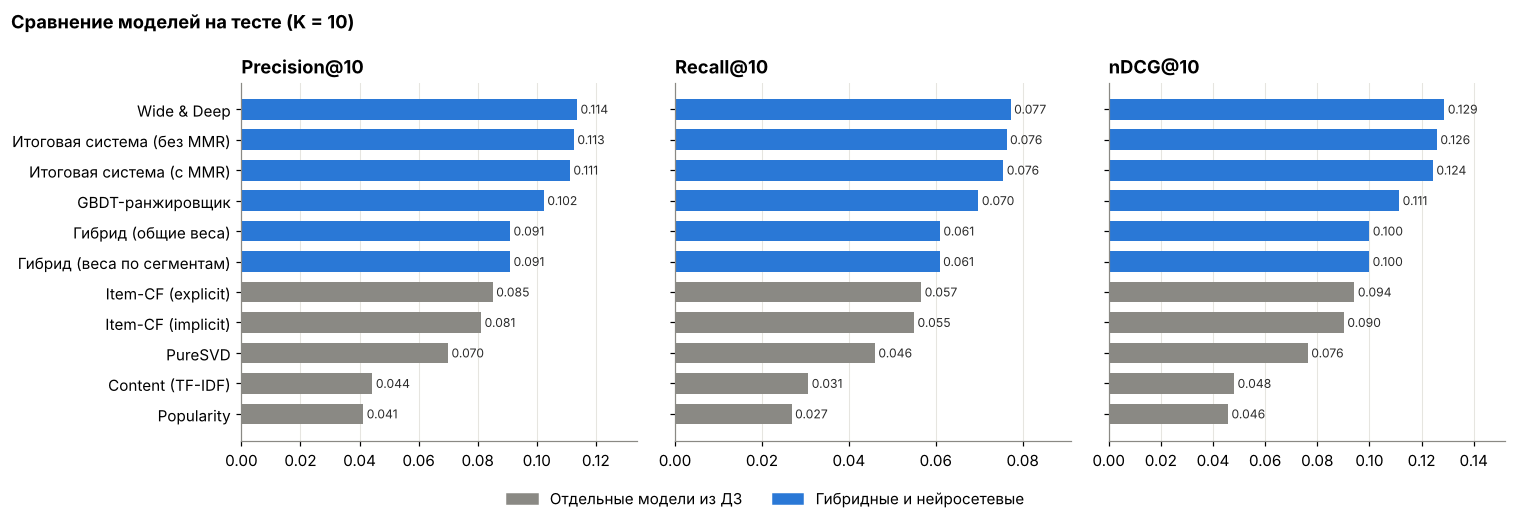

In [15]:
plots.model_comparison(metrics, FIG);

,Система,Сравнение с,Δ nDCG@10,"95% ДИ, низ","95% ДИ, верх","Относительно, %"
0,Гибрид (общие веса),Item-CF (explicit),0.0057,0.0050,0.0064,6.0848
1,Гибрид (веса по сегментам),Item-CF (explicit),0.0057,0.0049,0.0064,6.0192
2,GBDT-ранжировщик,Item-CF (explicit),0.0172,0.0160,0.0184,18.2317
3,Wide & Deep,Item-CF (explicit),0.0345,0.0332,0.0358,36.6238
4,Итоговая система (без MMR),Item-CF (explicit),0.0317,0.0307,0.0327,33.5908
5,Итоговая система (с MMR),Item-CF (explicit),0.0301,0.0291,0.0312,31.9726


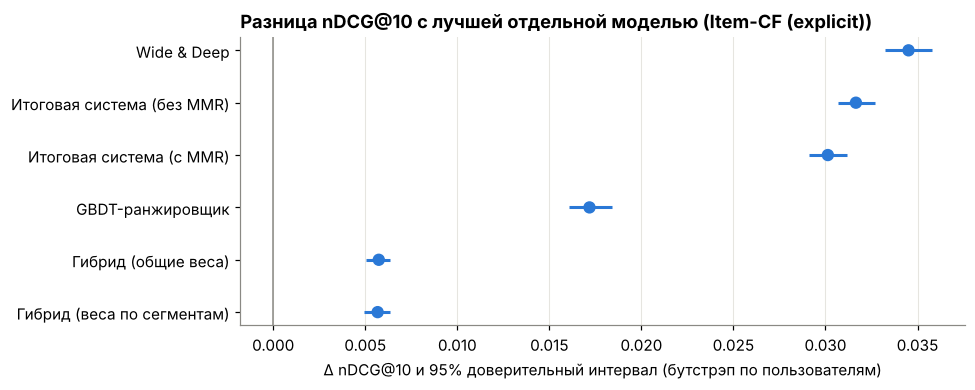

In [16]:
display(pipe.results["bootstrap_test"].round(4))
plots.bootstrap(pipe.results["bootstrap_test"], FIG);

**Сравнение гибридной системы с отдельными моделями.**

* Числа отдельных моделей совпадают с домашним заданием (Item-CF explicit: nDCG@10 = 0,094 в обеих работах),
  значит, сравнение корректно.
* **Взвешенный гибрид классических моделей** даёт надёжный, но умеренный прирост: +6% nDCG@10 к лучшей
  отдельной модели. Линейная смесь не умеет менять вес модели в зависимости от книги и пользователя.
* **Ранжировщики на расширенных признаках** дают основной выигрыш: GBDT +18%, Wide & Deep +37%. Они
  учатся, *когда* доверять каждой модели: например, ставить выше книги, которые рекомендуют сразу несколько
  моделей, или книги любимого автора.
* **Итоговая система** (+32%) немного уступает чистой Wide & Deep (−3,3% nDCG@10, без MMR −2,2%). На validation
  было наоборот: смесь с α = 0,8–0,9 была на 3–5% лучше. Вероятная причина — на тесте история пользователей
  длиннее (train_full), и нейросеть, использующая эмбеддинги всей истории, выигрывает от этого больше, чем
  линейный гибрид. Параметры выбраны по validation, и подгонять их под тест было бы некорректно. Практический
  вывод: перед внедрением сравнить α = 1 и выбранные α в A/B-тесте.
* Интервалы бутстрэпа узкие (±0,001), поэтому даже разница в 0,003 между итоговой системой и W&D статистически
  устойчива. Это разница в офлайн-метрике, а не обязательно в пользовательском опыте.
* Доля релевантных книг теста внутри пула — 34,5%. Это потолок для любого ранжировщика на этом пуле;
  улучшение генерации кандидатов (например, ANN-поиск по эмбеддингам W&D) — следующий резерв качества.

### 6.1. Точность против разнообразия и покрытия

,nDCG@10,Coverage@10,Novelty@10,ILD@10,LongTail@10
Модель,,,,,
Popularity,0.0458,0.0060,8.1452,0.4717,0.0000
Content (TF-IDF),0.0481,0.6387,12.8131,0.2805,0.5887
Item-CF (implicit),0.0902,0.5669,10.9022,0.6106,0.2715
Item-CF (explicit),0.0942,0.6554,11.1729,0.5546,0.3349
PureSVD,0.0764,0.3394,11.8357,0.5933,0.2866
Гибрид (общие веса),0.1000,0.5584,11.2518,0.5677,0.2966
Гибрид (веса по сегментам),0.0999,0.5651,11.2919,0.5612,0.3033
GBDT-ранжировщик,0.1114,0.6934,11.3712,0.6185,0.3389
Wide & Deep,0.1287,0.4631,11.3083,0.6073,0.3374


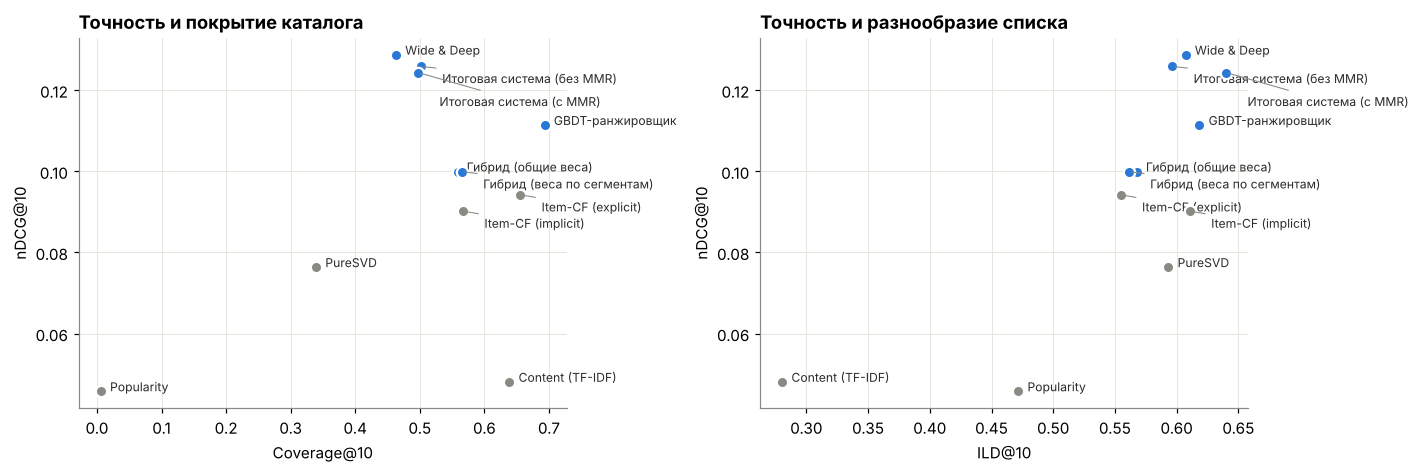

In [17]:
plots.accuracy_vs_diversity(metrics, FIG);
display(metrics[["nDCG@10", "Coverage@10", "Novelty@10", "ILD@10", "LongTail@10"]].round(4))

* **Точность и разнообразие не обязаны противоречить друг другу.** Итоговая система с MMR одновременно в 1,3 раза
  точнее Item-CF и даёт самый разнообразный список (ILD@10 = 0,640 — максимум среди всех моделей).
* **Покрытие каталога у нейросети ниже, чем у Item-CF** (46% против 66% книг хотя бы раз попадают в чей-то топ-10),
  а доля «длинного хвоста» практически равна (0,31–0,34). Ранжировщик, обученный на лайках, немного
  смещён к популярным книгам. Это нормальная плата за точность, но в продукте её стоит контролировать отдельной
  метрикой и при необходимости добавить в MMR штраф за популярность.
* Популярность — крайний случай: 0,6% каталога и ни одной книги из хвоста. Контентная модель — обратный
  крайний случай: высокое покрытие и много хвоста, но списки однородны по теме (ILD = 0,28) и неточны.

### 6.2. Эффективность для разных сегментов пользователей

,Пользователей
Активные (>50),37490
Умеренные (11–50),15574
Новые (≤10 лайков),239


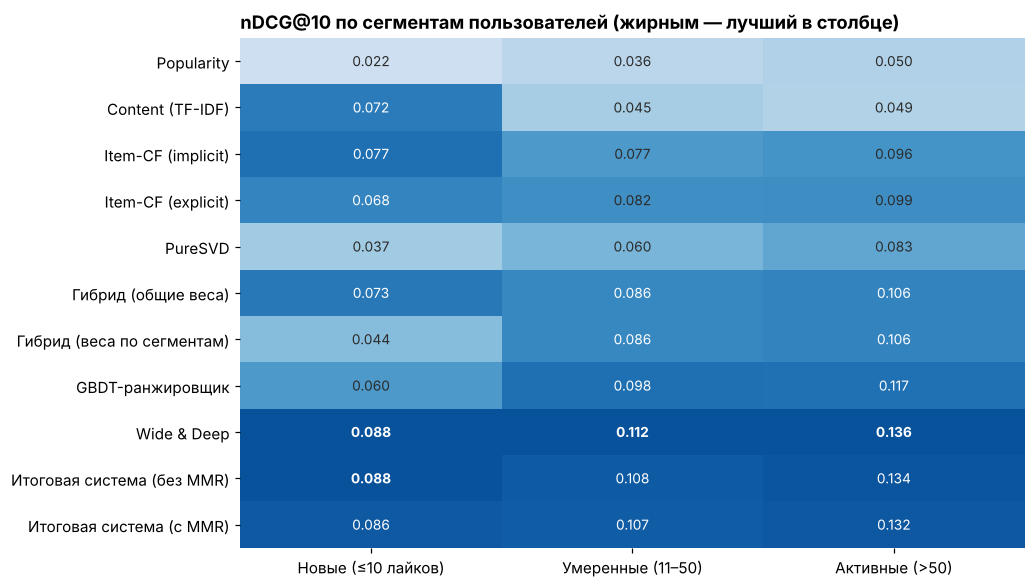

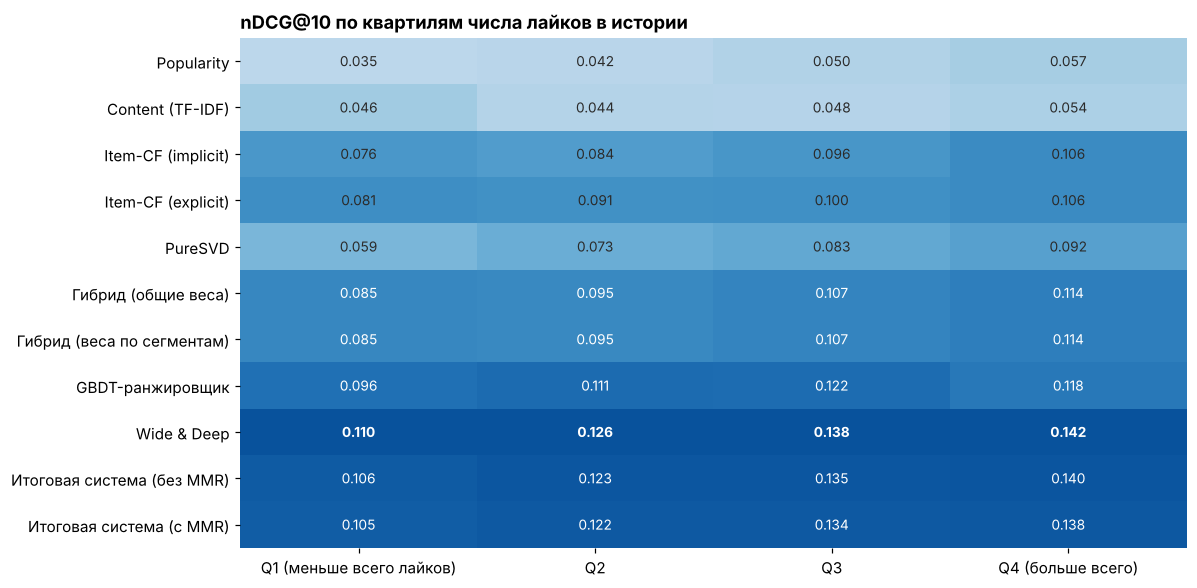

In [18]:
display(pipe.results["segment_sizes_test"])
seg_table = pipe.results["segments_test"][pipe.seg_labels]
plots.segment_heatmap(seg_table, FIG);
quart = pipe.results["activity_quartiles_test"]
plots.segment_heatmap(quart, FIG, "10b_activity_quartiles", "nDCG@10 по квартилям числа лайков в истории");

Естественных новых пользователей в тесте единицы, поэтому их поведение проверено симуляцией: у 5 000
тестовых пользователей оставлены только первые 1, 3, 5 или 10 понравившихся книг из `train_full`,
модели не переобучаются.

Лайков в истории,1,3,5,10
Модель,,,,
Content (TF-IDF),0.0173,0.0208,0.0232,0.0260
GBDT-ранжировщик,0.0281,0.0306,0.0335,0.0386
Item-CF (explicit),0.0042,0.0198,0.0254,0.0326
Item-CF (implicit),0.0153,0.0215,0.0246,0.0294
Popularity,0.0269,0.0277,0.0284,0.0299
PureSVD,0.0161,0.0184,0.0217,0.0248
Wide & Deep,0.0365,0.0387,0.0408,0.0473
Гибрид (веса по сегментам),0.0253,0.0275,0.0299,0.0322
Гибрид (общие веса),0.0204,0.0245,0.0276,0.0336


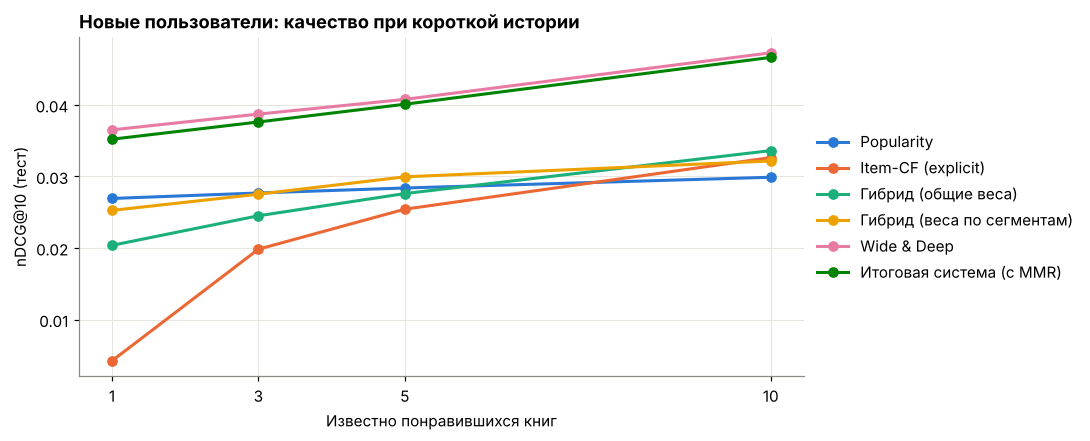

In [19]:
cold = pipe.results["cold_start_test"]
display(cold.pivot(index="Модель", columns="Лайков в истории", values="nDCG@10").round(4))
plots.cold_start(cold, ["Popularity", "Item-CF (explicit)", "Гибрид (общие веса)", "Гибрид (веса по сегментам)",
                        "Wide & Deep", "Итоговая система (с MMR)"], FIG);

**Эффективность для разных сегментов.**

* **Активные и умеренные пользователи.** Wide & Deep и итоговая система лидируют в обоих сегментах с одинаковым
  относительным выигрышем: +36% и +32% к Item-CF explicit у активных, +37% и +30% у умеренных. По квартилям
  активности картина та же: выигрыш стабилен от Q1 до Q4, то есть модель не «покупает» точность только на
  самых активных.
* **Естественные новички** (≤ 10 лайков в train) — всего 239 пользователей, оценки по ним шумные. Это не
  новые, а «строгие» пользователи: оценок у них много, а четвёрок и пятёрок мало. Поэтому взвешенный гибрид
  с весами сегмента «новые» (84% популярности), подобранными на симулированных новичках, здесь проигрывает
  общим весам (0,044 против 0,073). Нейросеть с этой группой справляется лучше всех (0,088): она видит
  признаки пользователя и не путает строгого читателя с новым. Вывод: сегментацию стоит делать не только по
  числу лайков, но и по числу оценок.
* **Холодный старт (симуляция).** При 1 известном лайке Item-CF почти бесполезен (0,004), популярность даёт
  0,027, классический гибрид с сегментными весами — 0,025, а итоговая система — 0,035 (+31% к популярности).
  С ростом истории разрыв сохраняется: при 10 лайках итоговая система даёт 0,047 против 0,030 у популярности
  и 0,033 у Item-CF. Нейросеть, обученная в том числе на укороченных историях, — лучший способ работать с новыми
  пользователями в этой системе.

## 7. Сквозной пайплайн и выдача рекомендаций

Все шаги, выполненные выше, — методы класса `Pipeline` (`src/recsys_pj/pipeline.py`):

| Этап | Метод | Что делает |
|---|---|---|
| Загрузка | `load` | Скачивает и читает CSV, очищает теги |
| Предобработка | `preprocess` | Разбиение по времени, TF-IDF, темы NMF, эмбеддинги |
| Обучение | `fit_stage` = `fit_base` → `build_tuning` → `tune_hybrid` → `build_ranker_data` → `train_neural` → `train_baselines` → `tune_blend` | Модели на train_fit, подбор весов, Wide & Deep, α и λ на validation |
| Переобучение | `refit_stage` | Базовые модели на train_full |
| Рекомендации и оценка | `evaluate_stage` | Пул кандидатов → скоринг → MMR → метрики на тесте и для новичков |
| Сохранение | `save` | CSV в `results/`, топ-10 для всех пользователей, обученная система в `models/` |

`Pipeline(cfg).run()` выполняет всё подряд; из командной строки — `python -m recsys_pj.pipeline --data-dir <папка>`.
Для новых данных того же формата достаточно указать другую папку: разбиение, обучение, подбор весов и
оценка выполняются заново. Ключ `--quick` прогоняет пайплайн на уменьшенных выборках за ~3 минуты.

In [20]:
pipe.save()
timings = pd.DataFrame(pipe.timer.rows)
display(timings)
print(f"Весь пайплайн в ноутбуке: {(time.perf_counter() - started_all) / 60:.1f} мин")

▶ 6. Сохранение результатов и модели


  готово за 1 с


,Этап,"Время, с"
0,1. Загрузка данных,3.3
1,"2. Предобработка: разбиение, TF-IDF, темы",5.1
2,3.1. Базовые модели на train_fit,25.0
3,3.2. Пул кандидатов и признаки для validation,26.2
4,3.3. Подбор весов гибрида (общих и по сегментам),50.5
5,3.4. Данные для ранжировщиков,39.9
6,3.5. Обучение Wide & Deep,97.3
7,3.6. Классический ранжировщик и абляции,161.8
8,3.7. Смесь Wide & Deep с гибридом по сегментам...,22.2
9,4. Переобучение базовых моделей на train_full,25.9


Весь пайплайн в ноутбуке: 10.7 мин


Обученная система сохраняется целиком (`models/recsys_system.pkl`) и отвечает на два вида запросов без
переобучения: для известного пользователя и для **нового пользователя по нескольким оценкам**.

In [21]:
from recsys_pj.pipeline import RecommenderSystem
import pickle

with open(cfg.models_dir / "recsys_system.pkl", "rb") as f:
    system: RecommenderSystem = pickle.load(f)

user_id = 2
liked = sp_.train_full[(sp_.train_full["user_id"] == user_id) & (sp_.train_full["rating"] >= 4)]
print(f"Пользователь {user_id}: {len(liked)} понравившихся книг, например:")
display(pipe.raw.books.set_index("book_id").loc[liked["book_id"].head(5), ["title", "authors"]])
print("Рекомендации итоговой системы:")
display(system.recommend(user_id, n=10))

Пользователь 2: 41 понравившихся книг, например:


,title,authors
book_id,,
4081,I am Charlotte Simmons,Tom Wolfe
260,How to Win Friends and Influence People,Dale Carnegie
9296,The Drama of the Gifted Child: The Search for ...,"Alice Miller, Ruth Ward"
26,"The Da Vinci Code (Robert Langdon, #2)",Dan Brown
33,Memoirs of a Geisha,Arthur Golden


Рекомендации итоговой системы:


,book_id,Название,Автор
0,4,To Kill a Mockingbird,Harper Lee
1,92,Freakonomics: A Rogue Economist Explores the H...,Steven D. Levitt
2,23,Harry Potter and the Chamber of Secrets (Harry...,J.K. Rowling
3,688,Under the Banner of Heaven: A Story of Violent...,Jon Krakauer
4,181,In Cold Blood,Truman Capote
5,247,The 7 Habits of Highly Effective People: Power...,Stephen R. Covey
6,1,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins
7,18,Harry Potter and the Prisoner of Azkaban (Harr...,J.K. Rowling
8,32,Of Mice and Men,John Steinbeck
9,25,Harry Potter and the Deathly Hallows (Harry Po...,J.K. Rowling


In [22]:
titles = pipe.raw.books.set_index("book_id")["title"]
new_user = {int(titles[titles.str.startswith("The Hobbit")].index[0]): 5,
            int(titles[titles.str.startswith("A Game of Thrones")].index[0]): 5,
            int(titles[titles.str.startswith("The Name of the Wind")].index[0]): 4}
print("Новый пользователь оценил:", {titles[b]: r for b, r in new_user.items()})
display(system.recommend_new_user(new_user, n=10))

Новый пользователь оценил: {'The Hobbit': 5, 'A Game of Thrones (A Song of Ice and Fire, #1)': 5, 'The Name of the Wind (The Kingkiller Chronicle, #1)': 4}


,book_id,Название,Автор
0,1,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins
1,30,Gone Girl,Gillian Flynn
2,307,"The Wise Man's Fear (The Kingkiller Chronicle,...",Patrick Rothfuss
3,4,To Kill a Mockingbird,Harper Lee
4,2,Harry Potter and the Sorcerer's Stone (Harry P...,J.K. Rowling
5,450,"Storm Front (The Dresden Files, #1)",Jim Butcher
6,16,"The Girl with the Dragon Tattoo (Millennium, #1)",Stieg Larsson
7,70,"Ender's Game (Ender's Saga, #1)",Orson Scott Card
8,20,"Mockingjay (The Hunger Games, #3)",Suzanne Collins
9,17,"Catching Fire (The Hunger Games, #2)",Suzanne Collins


Рекомендации осмысленны. Пользователю 2, который читает нон-фикшн, психологию и популярную прозу,
система предлагает «Фрикономику», «7 навыков высокоэффективных людей», «Хладнокровное убийство» и
классику. Новому пользователю, оценившему три фэнтези-книги, система предлагает продолжение «Имени ветра»
(«Страхи мудреца»), «Досье Дрездена», «Игру Эндера», но также бестселлеры вне жанра («Голодные игры»,
«Исчезнувшая»). При трёх лайках система закономерно опирается на популярность. Заметен и недостаток: третья
часть «Голодных игр» стоит выше второй. Признак «следующая книга серии» — очевидное улучшение.

## 8. Выводы

### 8.1. Что сделано

| Требование задания | Где выполнено | Результат |
|---|---|---|
| Расширенные признаки пользователей, книг и взаимодействий | Раздел 3, `features.py` | 32 признака; +13% nDCG@10 к ранжировщику на одних скорах моделей |
| Взвешенное усреднение моделей | Раздел 4.2, `hybrid.py` | +6% к лучшей модели ДЗ |
| Разделение пользователей по типам | Разделы 4.2, 5.3, 6.2 | Свои веса и доля нейросети для новых / умеренных / активных |
| Комбинирование персонализированных и популярных | Раздел 4.2 | Популярность — 84% веса у новых, 14% у остальных |
| Пул кандидатов от всех моделей, фильтр прочитанного | Раздел 4.1 | ~176 книг на пользователя; проверка `assert` на тесте |
| Баланс релевантности и разнообразия | Раздел 5.3, MMR | ILD@10 +7% ценой −1,2% nDCG@10 на тесте |
| Сравнение с отдельными моделями, сегменты, оптимизация весов | Раздел 6 | Таблицы, графики, бутстрэп-интервалы |
| Нейросетевая архитектура | Раздел 5, `neural.py` | Wide & Deep: +37% nDCG@10 к лучшей модели ДЗ |
| Интеграция в гибрид и сравнение с классикой | Разделы 5.2–5.3, 6 | Смесь с гибридом; GBDT и абляции на тех же признаках |
| Сквозной пайплайн с повторным запуском | Раздел 7, `pipeline.py` | Одна команда, ~13 минут, результаты воспроизводятся |

### 8.2. Сильные и слабые стороны подходов

| Подход | Сильные стороны | Слабые стороны |
|---|---|---|
| Popularity | Работает без истории, безопасный выбор для новичков | Один список для всех, 0,6% каталога, нет «длинного хвоста» |
| Content (TF-IDF) | Не нужен поведенческий сигнал, большое покрытие, объяснимость | Низкая точность, однообразные по теме списки |
| Item-CF (explicit / implicit) | Лучшая классическая точность, понятные «похожие книги» | Бесполезен при 1–3 лайках, квадратичная стоимость схожести |
| PureSVD | Компактные факторы, быстрый скоринг | Уступает Item-CF на этих данных, смещение к популярным |
| Взвешенный гибрид | Прост, прозрачен, устойчив к выбору весов | Линейная смесь: вес модели не зависит от пары «пользователь — книга» |
| GBDT-ранжировщик | Сильный бейзлайн, без настройки архитектуры | Хуже переносит знания на короткие истории |
| Wide & Deep | Максимальная точность, работает для новых пользователей без переобучения | Нужны пул кандидатов и обучение; ниже покрытие каталога; Wide-часть мало добавляет |

### 8.3. Рекомендации по выбору моделей

1. **Архитектура «кандидаты → ранжирование» оправдана:** простые модели генерируют разнообразный пул, а обученный
   ранжировщик на расширенных признаках даёт основной прирост (+18% у GBDT, +37% у Wide & Deep). Улучшать
   ранжировщик выгоднее, чем подбирать веса линейной смеси (+6%).
2. **Для продукта** — итоговая система: Wide & Deep поверх пула кандидатов, смешанная с классическим гибридом,
   и MMR с λ ≈ 0,85. Перед внедрением стоит проверить в A/B-тесте долю нейросети α = 1, которая на тесте
   оказалась на 2–3% точнее выбранной по validation.
3. **Для новых пользователей** нейросеть с эмбеддингом пользователя как средним эмбеддингов книг лучше
   популярности уже с первого лайка. Если обучать нейросеть нельзя, нужны веса с упором на популярность (84%),
   но новичков стоит отличать от «строгих» пользователей по числу оценок, а не только лайков.
4. **Если важна простота и объяснимость** — взвешенный гибрид классических моделей: на 6% точнее Item-CF,
   почти без затрат на обучение.

### 8.4. Ограничения и что улучшить

Часть этих направлений проверена в разделе 9: новые источники кандидатов, признаки серий, LambdaMART и SASRec подняли nDCG@10 до 0,183.

* **Офлайн-оценка.** Время в данных восстановлено по порядку строк, а рекомендации оцениваются по тому, что
  пользователь выбрал сам (пропуски не случайны). Итоговый выбор нужно подтверждать онлайн-экспериментом.
* **Потолок пула.** В пул попадает 34,5% релевантных книг теста; можно добавить кандидатов из ANN-поиска по
  эмбеддингам Wide & Deep (Two-Tower-генерация) и из следующих книг серии.
* **Покрытие.** Нейросеть смещена к популярным книгам: стоит добавить в MMR штраф за популярность или
  ограничение на долю хвоста.
* **Архитектура.** Deep-часть в одиночку не хуже полной Wide & Deep: можно упростить модель или добавить в
  Wide-часть содержательные пересечения (автор × история, серия × прочитанные части).

## 9. Исследование направлений улучшения и проверка гипотез

### 9.1. Что показало исследование

После построения системы проведено отдельное исследование методов 2023–2026 годов: генерация кандидатов,
последовательные модели, обучение ранжированию, признаки, LLM, холодный старт, разнообразие и методология оценки
(аналитическая записка). Главный вывод диагностики: **узкое место — генерация кандидатов, а не ранжировщик.**
В пул попадает лишь 34,5% релевантных книг теста, поэтому любой ранжировщик работает примерно на трети возможного
качества. Из записки отобраны гипотезы, которые реализуемы на CPU за разумное время и проверяемы абляцией:

| № | Гипотеза | Что решает | Как проверяем |
|---|---|---|---|
| H0 | Порядок строк `ratings.csv` отражает время | Условие для последовательных моделей | Доля пар «часть N раньше части N+1» в сериях (50% — случайный порядок) |
| H1 | Новые источники кандидатов **EASE** (Steck, 2019) и **RP3beta** (Paudel et al., 2017) | Низкий recall пула | Recall@50 источников и пула на validation; W&D на пуле C0 → C1 |
| H2 | **Признаки серий книг** («следующая непрочитанная часть», пропущенные части) и правило порядка частей | Ошибка из демо: 3-я часть «Голодных игр» выше 2-й | W&D C1 → C2; правило — на validation |
| H3 | **LambdaMART** (LightGBM lambdarank) вместо поточечного GBDT | Нечестное сравнение нейросети с бустингом | LambdaMART против GBDT pointwise на одних признаках |
| H4 | **Честный выбор смеси**: веса гибрида — на половине A пользователей, смесь — на половине B, смесь принимается только при значимом выигрыше (бутстрэп) | Расхождение validation/test у α | Таблица выбора и результат на тесте |
| H5 | **SASRec** с полной cross-entropy (Kang & McAuley, 2018; Klenitskiy & Vasilev, 2023) как источник кандидатов и признак ранжировщика | Не используется порядок взаимодействий | W&D C2 → C3 |

Отложены как требующие GPU или несоразмерные масштабу 10 000 книг: LLM-переранжирование, генеративные модели
(HSTU, TIGER), ELSA, Two-Tower с ANN, калибровка и DPP. Они перечислены в выводах как следующий шаг.

Все гипотезы проверяются **кумулятивными абляциями на одних и тех же пользователях**: C0 — пул и признаки проекта,
C1 — плюс EASE и RP3beta, C2 — плюс признаки серий, C3 — плюс SASRec. Разбиение, метрики и тестовые
пользователи те же, что в разделах 2–8. Для экономии памяти данные прежних шагов освобождаются.

In [23]:
from recsys_pj.improvement_study import ImprovementStudy, StudyConfig
import gc
for attr in ("train_data", "valid_data", "tuning"):
    if hasattr(pipe, attr):
        delattr(pipe, attr)
gc.collect()
study = ImprovementStudy(pipe, StudyConfig())
study.check_order()
display(study.results["h0_order"].round(3))
display(study.results["series_stats"])

▶ 9.1. H0: порядок строк и серии книг


  готово за 1 с


,Пара частей,Число пар,"Доля, где N оценена раньше"
0,N и N+1,991039,0.762
1,N и N+2,635872,0.790
2,N и N+3,399468,0.791


,Значение
Книг в сериях,4205
Серий,1648
Серий с 2+ книгами в каталоге,816


**H0 подтверждена.** Если одному пользователю нравятся части N и N+1 одной серии, то в 76% случаев часть N оценена
раньше (при случайном порядке было бы 50%). Для частей через одну и через две — 79%. Значит, порядок строк несёт
информацию о времени, хотя и не строго: часть оценок, видимо, ставится пачками задним числом. Последовательные
модели здесь применимы. В каталоге 4 205 книг из 1 648 серий, у 816 серий есть хотя бы две книги, поэтому признаки
серий затрагивают заметную долю пула.

### 9.2. H1 и H5: новые источники кандидатов

EASE — линейный автоэнкодер с замкнутым решением $W = I - P\,\mathrm{diag}(1/\mathrm{diag}\,P)$,
$P = (X^\top X + \lambda I)^{-1}$; на 10 000 книг обращение матрицы занимает секунды. RP3beta — случайное
блуждание «пользователь → книга → пользователь → книга» со штрафом популярности $\text{pop}^{-\beta}$.
Параметры $\lambda$ и $\beta$ подбираются по Recall@50 на validation. SASRec — двухслойный трансформер
(размерность 64, окно 50 последних оценок), обучается предсказывать следующую оценённую книгу с полной
softmax cross-entropy по 10 000 книг; лучшая эпоха выбирается по Recall@50 на validation.

▶ 9.2. H1: EASE и RP3beta (подбор λ и β на validation)


    Модель  Параметр  val Recall@50
0     EASE   λ = 250         0.2418
1     EASE  λ = 1000         0.2418
2     EASE  λ = 4000         0.2255
3  RP3beta   β = 0.3         0.2055
4  RP3beta   β = 0.5         0.2079
5  RP3beta   β = 0.7         0.1642
  готово за 53 с
▶ 9.3. H5: обучение SASRec (cross-entropy, CPU)


  [SASRec] эпоха=1, loss=8.0058, время, с=267.1353, val Recall@50=0.1368


  [SASRec] эпоха=2, loss=6.8524, время, с=260.3782, val Recall@50=0.2401


  [SASRec] эпоха=3, loss=6.2754, время, с=268.6998, val Recall@50=0.2576


  [SASRec] эпоха=4, loss=6.1000, время, с=259.8516, val Recall@50=0.2598
  готово за 1060 с
▶ 9.4. Доля релевантных книг по источникам и в пуле (validation)


                   Источник  Recall@50  Recall@100  Размер пула
0                Popularity     0.0976      0.1481          NaN
1          Content (TF-IDF)     0.1147      0.1726          NaN
2        Item-CF (implicit)     0.2120      0.2986          NaN
3        Item-CF (explicit)     0.1888      0.2618          NaN
4                   PureSVD     0.1681      0.2377          NaN
5                      EASE     0.2418      0.3606          NaN
6                   RP3beta     0.2079      0.3160          NaN
7                    SASRec     0.2598      0.3558          NaN
8   Пул C0 (топ-50 каждого)     0.4034         NaN     175.8623
9   Пул C1 (топ-50 каждого)     0.4440         NaN     193.0683
10  Пул C3 (топ-50 каждого)     0.5124         NaN     220.3850
  готово за 7 с


,Модель,Параметр,val Recall@50
0,EASE,λ = 250,0.2418
1,EASE,λ = 1000,0.2418
2,EASE,λ = 4000,0.2255
3,RP3beta,β = 0.3,0.2055
4,RP3beta,β = 0.5,0.2079
5,RP3beta,β = 0.7,0.1642


,эпоха,loss,"время, с",val Recall@50
0,1,8.0058,267.1353,0.1368
1,2,6.8524,260.3782,0.2401
2,3,6.2754,268.6998,0.2576
3,4,6.1000,259.8516,0.2598


,Источник,Recall@50,Recall@100,Размер пула
0,Popularity,0.0976,0.1481,NaN
1,Content (TF-IDF),0.1147,0.1726,NaN
2,Item-CF (implicit),0.2120,0.2986,NaN
3,Item-CF (explicit),0.1888,0.2618,NaN
4,PureSVD,0.1681,0.2377,NaN
5,EASE,0.2418,0.3606,NaN
6,RP3beta,0.2079,0.3160,NaN
7,SASRec,0.2598,0.3558,NaN
8,Пул C0 (топ-50 каждого),0.4034,NaN,175.8623
9,Пул C1 (топ-50 каждого),0.4440,NaN,193.0683


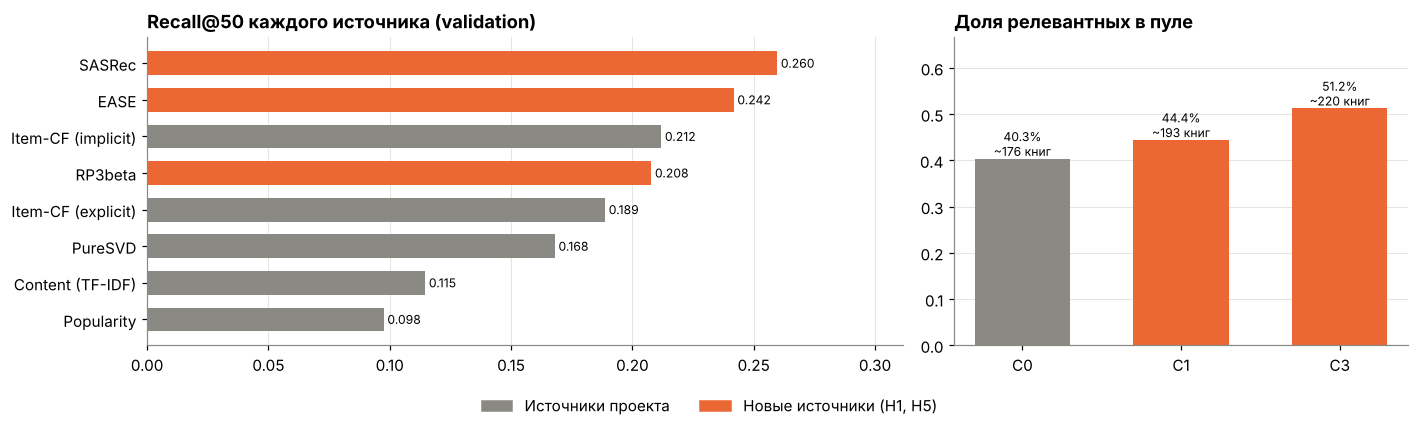

In [24]:
study.fit_sources()
display(study.results["source_tuning"].round(4))
display(study.results["sasrec_history"].round(4))
display(study.results["source_recall_val"].round(4))
plots.source_recall(study.results["source_recall_val"], FIG);

**H1 и H5: новые источники заметно расширяют пул.**

* **EASE** — лучший источник среди классических: Recall@50 = 0,242 против 0,212 у лучшего источника проекта (Item-CF implicit),
  то есть +14%. Значения λ = 250 и λ = 1000 дают одинаковый результат, слишком сильная регуляризация (λ = 4000) хуже.
  **RP3beta** (β = 0,5) находится на уровне Item-CF (0,208), но, как будет видно на тесте, даёт заметно больше
  книг из «длинного хвоста».
* **SASRec — сильнейший отдельный источник** (0,260), хотя обучался всего 4 эпохи на CPU (~4,4 мин на эпоху). Recall
  всё ещё растёт (0,258 → 0,260 за последнюю эпоху), поэтому на GPU-станции его можно усилить.
* **Пул кандидатов:** доля релевантных книг validation в пуле растёт с 40,3% (C0, ~176 книг) до 44,4% (C1, ~193 книги)
  и 51,2% (C3, ~220 книг). Потолок качества поднимается на 11 п. п., а пул вырастает всего на четверть.

### 9.3. Абляции ранжировщиков на validation (H1, H2, H3, H5)

Для каждой конфигурации C0–C3 Wide & Deep обучается заново (ранняя остановка на половине A), качество
сравнивается на половине B. Для C0 и C3 дополнительно обучается LambdaMART, для C3 — поточечный GBDT, как в разделе 5.

In [25]:
study.build_data().train_rankers()
display(study.results["ablation_val"].round(4))

▶ 9.5. Расширенный пул кандидатов и признаки для validation


  строк для обучения: 2,787,752; средний пул (8 источников): 221
  готово за 54 с
▶ 9.6. Wide & Deep: C0: 5 источников из проекта


  {'Вариант': 'C0: 5 источников из проекта', 'Ранжировщик': 'Wide & Deep', 'Средний пул': 176.15933333333334, 'Доля релевантных в пуле': 0.41833532187340233, 'nDCG@10 (полные истории)': 0.09289697475386853, 'nDCG@10 (укороченные)': 0.03518075811593157}


  {'Вариант': 'C0: 5 источников из проекта', 'Ранжировщик': 'LambdaMART (H3)', 'Средний пул': 176.15933333333334, 'Доля релевантных в пуле': 0.41833532187340233, 'nDCG@10 (полные истории)': 0.09869379981775192, 'nDCG@10 (укороченные)': 0.03536501467756352}


  готово за 93 с
▶ 9.6. Wide & Deep: C1: + EASE и RP3beta


  {'Вариант': 'C1: + EASE и RP3beta', 'Ранжировщик': 'Wide & Deep', 'Средний пул': 193.10066666666665, 'Доля релевантных в пуле': 0.45490746362054413, 'nDCG@10 (полные истории)': 0.09683839269897876, 'nDCG@10 (укороченные)': 0.03343939367125758}
  готово за 55 с
▶ 9.6. Wide & Deep: C2: + признаки серий


... (2 outputs left out)

  {'Вариант': 'C3: + SASRec', 'Ранжировщик': 'Wide & Deep', 'Средний пул': 220.42466666666667, 'Доля релевантных в пуле': 0.5250363808075883, 'nDCG@10 (полные истории)': 0.15891021594582083, 'nDCG@10 (укороченные)': 0.030850468667841607}


  {'Вариант': 'C3: + SASRec', 'Ранжировщик': 'LambdaMART (H3)', 'Средний пул': 220.42466666666667, 'Доля релевантных в пуле': 0.5250363808075883, 'nDCG@10 (полные истории)': 0.1690956325185317, 'nDCG@10 (укороченные)': 0.032335479514891664}


  готово за 142 с


,Вариант,Ранжировщик,Средний пул,Доля релевантных в пуле,nDCG@10 (полные истории),nDCG@10 (укороченные)
0,C0: 5 источников из проекта,Wide & Deep,176.1593,0.4183,0.0929,0.0352
1,C0: 5 источников из проекта,LambdaMART (H3),176.1593,0.4183,0.0987,0.0354
2,C1: + EASE и RP3beta,Wide & Deep,193.1007,0.4549,0.0968,0.0334
3,C2: + признаки серий,Wide & Deep,193.1007,0.4549,0.1040,0.0330
4,C3: + SASRec,Wide & Deep,220.4247,0.5250,0.1589,0.0309
5,C3: + SASRec,LambdaMART (H3),220.4247,0.5250,0.1691,0.0323
6,C3: + SASRec,GBDT pointwise,220.4247,0.5250,0.1495,0.0252


**Абляции на validation (nDCG@10, полные истории):**

* **H1:** EASE и RP3beta в пуле дают +4% (0,0929 → 0,0968): ранжировщику доступно больше релевантных книг.
* **H2:** признаки серий дают ещё +7% (0,0968 → 0,1040), причём пул не меняется — растёт только качество ранжирования.
* **H5:** SASRec — главный скачок, +53% (0,1040 → 0,1589). Он работает одновременно как источник кандидатов (пул +7 п. п.)
  и как признак «что пользователь, скорее всего, прочитает следующим», которого не было ни у одной модели проекта.
* **H3:** **LambdaMART обгоняет Wide & Deep** на обоих наборах признаков: +6% на C0 и +6% на C3 (0,1691 против 0,1589).
  Поточечный GBDT на C3 (0,1495) уступает LambdaMART на 12%. Вывод раздела 5 о преимуществе нейросети над бустингом
  был следствием слабой поточечной постановки бустинга, а не преимуществом архитектуры.
* **Укороченные истории** (симуляция новичков) почти не выигрывают, а SASRec их даже немного ухудшает
  (0,035 → 0,031). Причина разобрана ниже, в результатах для новых пользователей.

### 9.4. H4: честный выбор итоговой смеси, MMR и правило серий

In [26]:
study.select_final()
display(study.results["hybrid_weights_ext"].round(3))
display(study.results["blend_choice"].round(4))
mmr_ext = study.results["mmr_rule_val"]
display(mmr_ext.pivot(index="λ", columns="Правило серий", values="nDCG@10").round(4))

▶ 9.7. H4: веса гибрида на половине A, выбор смеси, MMR и правила серий на половине B


              Сегмент  W&D (C3)               Лучшая смесь  nDCG@10 смеси       Δ  95% ДИ, низ  95% ДИ, верх Принято
0  Новые (≤10 лайков)    0.0312  W&D + LambdaMART, w = 0.6         0.0336  0.0024       0.0008        0.0040   смесь
1   Умеренные (11–50)    0.1398  W&D + LambdaMART, w = 0.9         0.1507  0.0109       0.0037        0.0181   смесь
2      Активные (>50)    0.1720  W&D + LambdaMART, w = 0.8         0.1819  0.0099       0.0051        0.0146   смесь


  λ = 0.8; правило серий: не принято
  готово за 33 с


,Popularity,Content (TF-IDF),Item-CF (implicit),Item-CF (explicit),PureSVD,EASE,RP3beta,SASRec
Новые (≤10 лайков),0.586,0.021,0.017,0.038,0.171,0.033,0.070,0.065
Умеренные (11–50),0.000,0.000,0.003,0.047,0.055,0.005,0.042,0.848
Активные (>50),0.039,0.000,0.012,0.035,0.030,0.000,0.000,0.884


,Сегмент,W&D (C3),Лучшая смесь,nDCG@10 смеси,Δ,"95% ДИ, низ","95% ДИ, верх",Принято
0,Новые (≤10 лайков),0.0312,"W&D + LambdaMART, w = 0.6",0.0336,0.0024,0.0008,0.0040,смесь
1,Умеренные (11–50),0.1398,"W&D + LambdaMART, w = 0.9",0.1507,0.0109,0.0037,0.0181,смесь
2,Активные (>50),0.1720,"W&D + LambdaMART, w = 0.8",0.1819,0.0099,0.0051,0.0146,смесь


Правило серий,False,True
λ,,
0.50,0.1312,0.1312
0.60,0.1494,0.1486
0.70,0.1609,0.1595
0.80,0.1659,0.1633
0.85,0.1673,0.1647
0.90,0.1683,0.1655
0.95,0.1687,0.1658
1.00,0.1692,0.1666


**H4: честный выбор смеси.**

* Веса взвешенного гибрида теперь подбираются на половине A, а смесь — на независимой половине B. У умеренных и
  активных пользователей 85–88% веса гибрида получает SASRec, у новичков 59% — популярность.
* Однако лучшим партнёром Wide & Deep оказался не гибрид, а LambdaMART. Смесь «W&D + LambdaMART» принята во всех
  трёх сегментах, потому что везде нижняя граница бутстрэп-интервала выигрыша больше нуля: +0,002 у новых,
  +0,011 у умеренных, +0,010 у активных.
* MMR: при λ = 0,8 потеря nDCG@10 на validation укладывается в допустимые 2%.
* **Правило порядка частей серии (H2b) отклонено.** Оно снижает nDCG@10 при любом λ (при λ = 1: 0,1692 → 0,1666).
  Как показала H0, в четверти случаев читатели оценивают части не по порядку, и жёсткое правило ломает правильные
  ответы. Ранжировщик с признаками серий учитывает порядок мягко и лучше. Это хороший пример гипотезы, которую
  проверка отвергла.

### 9.5. Результаты на тесте

▶ 9.8. Переобучение EASE и RP3beta на train_full


  готово за 16 с
▶ 9.9. Тест: все варианты улучшений


  [тест] доля релевантных книг в пуле: C0 34.7%, C3 43.5%


  готово за 350 с


,Доля релевантных книг теста в пуле
C0: 5 источников из проекта,0.3466
C3: + SASRec,0.4350


,Precision@5,Recall@5,nDCG@5,Precision@10,Recall@10,nDCG@10,Precision@20,Recall@20,nDCG@20,Coverage@10,Novelty@10,ILD@10,LongTail@10
Модель,,,,,,,,,,,,,
EASE,0.0926,0.0324,0.0958,0.0841,0.0581,0.0912,0.0740,0.1005,0.0975,0.4579,10.3209,0.6115,0.1478
RP3beta,0.0869,0.0301,0.0905,0.0779,0.0531,0.0852,0.0670,0.0899,0.0890,0.7031,11.5745,0.4340,0.4409
SASRec,0.1483,0.0485,0.1623,0.1157,0.0755,0.1374,0.0874,0.1136,0.1284,0.7287,12.0587,0.4001,0.4515
W&D C0,0.1290,0.0444,0.1362,0.1090,0.0740,0.1225,0.0877,0.1173,0.1221,0.4717,11.5501,0.6128,0.3806
W&D C1,0.1357,0.0468,0.1440,0.1141,0.0777,0.1290,0.0924,0.1243,0.1292,0.4846,11.3587,0.6389,0.3513
W&D C2,0.1411,0.0488,0.1499,0.1178,0.0804,0.1337,0.0948,0.1276,0.1333,0.4882,11.4167,0.6306,0.3594
W&D C3,0.1899,0.0636,0.2060,0.1512,0.1005,0.1771,0.1158,0.1531,0.1688,0.6338,11.6119,0.5380,0.3890
LambdaMART (C0),0.1362,0.0469,0.1457,0.1137,0.0775,0.1297,0.0911,0.1226,0.1287,0.6006,11.4611,0.5968,0.3496
LambdaMART (C3),0.1974,0.0663,0.2149,0.1567,0.1045,0.1843,0.1186,0.1570,0.1744,0.7186,11.4509,0.5109,0.3493


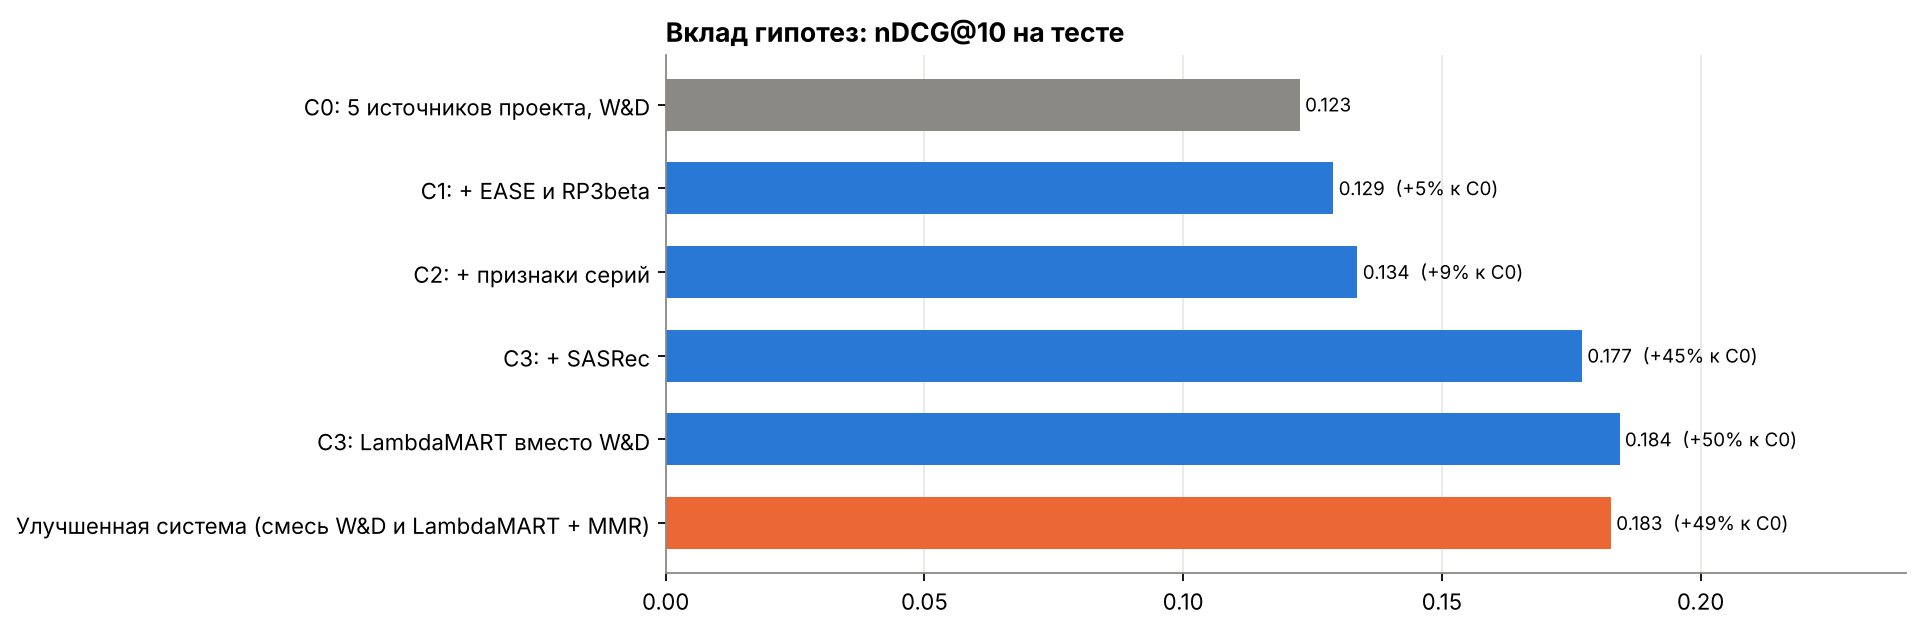

In [27]:
study.refit_full().evaluate_test()
ext = study.results["metrics_test_ext"]
display(study.results["pool_recall_test_ext"].round(4))
display(ext.round(4))
plots.ablation_steps(ext, [
    ("C0: 5 источников проекта, W&D", "W&D C0"),
    ("C1: + EASE и RP3beta", "W&D C1"),
    ("C2: + признаки серий", "W&D C2"),
    ("C3: + SASRec", "W&D C3"),
    ("C3: LambdaMART вместо W&D", "LambdaMART (C3)"),
    ("Улучшенная система (смесь W&D и LambdaMART + MMR)", "Улучшенная система (итог)"),
], FIG);

In [28]:
display(study.results["bootstrap_ext"].round(4))
seg_ext = study.results["segments_test_ext"]
display(seg_ext.round(4))

,Новая система,Сравнение с (проект),Δ nDCG@10,"95% ДИ, низ","95% ДИ, верх","Относительно, %"
0,Улучшенная система (итог),Итоговая система (с MMR),0.0583,0.0569,0.0596,46.8774
1,W&D C3,Итоговая система (с MMR),0.0527,0.0514,0.0541,42.3853
2,LambdaMART (C3),Итоговая система (с MMR),0.0600,0.0585,0.0614,48.2243
3,Улучшенная система (итог),Wide & Deep,0.0539,0.0526,0.0553,41.8771
4,W&D C3,Wide & Deep,0.0483,0.0470,0.0498,37.5379
5,LambdaMART (C3),Wide & Deep,0.0556,0.0542,0.0571,43.1782
6,Улучшенная система (итог),Item-CF (explicit),0.0884,0.0868,0.0900,93.8379
7,W&D C3,Item-CF (explicit),0.0828,0.0812,0.0844,87.9096
8,LambdaMART (C3),Item-CF (explicit),0.0901,0.0884,0.0918,95.6155


,Новые (≤10 лайков),Умеренные (11–50),Активные (>50)
EASE,0.0899,0.0806,0.0956
RP3beta,0.1048,0.0750,0.0893
SASRec,0.0887,0.1001,0.1531
W&D C0,0.0884,0.1062,0.1296
W&D C1,0.0818,0.1128,0.1361
W&D C2,0.0840,0.1178,0.1406
W&D C3,0.0942,0.1413,0.1925
LambdaMART (C0),0.0743,0.1138,0.1366
LambdaMART (C3),0.1101,0.1476,0.2001
GBDT pointwise (C3),0.0827,0.1284,0.1801


**Результаты на тесте подтверждают validation.**

* **Каждая гипотеза даёт вклад** (Wide & Deep, кумулятивно): C0 0,123 → C1 0,129 (+5%) → C2 0,134 (+9%) →
  C3 0,177 (+45%). LambdaMART на C3 даёт 0,184 (+50%). Значения C0 здесь ниже, чем у W&D в разделе 6 (0,129),
  потому что ранжировщики исследования обучены на вдвое меньшей выборке (12 500 историй против 25 000) для экономии
  памяти. Поэтому прирост гипотез оценивается внутри раздела 9, а сравнение с проектом — парным бутстрэпом.
* **Доля релевантных книг теста в пуле:** 34,7% → 43,5% (+25% относительно). Главная слабость, найденная в исследовании,
  частично устранена.
* **Улучшенная система** (смесь W&D и LambdaMART + MMR): nDCG@10 = 0,183, Precision@10 = 0,155, Recall@10 = 0,104.
  Это на **47% лучше итоговой системы проекта** (95% ДИ прироста nDCG@10: +0,057…+0,060) и на 94% лучше
  Item-CF из ДЗ. Без MMR — 0,186: в отличие от раздела 6, смесь на тесте лучше обеих частей по отдельности, то есть
  честная процедура выбора устранила расхождение validation/test.
* **Одна модель SASRec по всему каталогу** (0,137) точнее всей системы проекта (0,124) и её лучшей части W&D (0,129).
  Порядок чтения — самый сильный неиспользованный сигнал в этих данных: серии, авторы и периоды увлечений.
* **Смещение к популярному исправлено:** покрытие каталога 70% против 50% у итоговой системы проекта и 66% у Item-CF,
  доля «длинного хвоста» 0,33 против 0,31. MMR снижает nDCG@10 на 1,6%, а разнообразие списка ILD@10 повышает на 13%
  (0,515 → 0,582).
* **По сегментам** выигрыш есть везде, больше всего у активных: +50% к итоговой системе проекта (0,198 против 0,132),
  у умеренных +37%, у естественных новичков +36%. Чем длиннее последовательность, тем больше пользы от SASRec.

▶ 9.10. Новые пользователи: улучшенная и прежняя системы на одних пользователях


  [n=1] доля релевантных книг в пуле: C0 16.8%, C3 16.9%


  [n=1, проект] доля релевантных книг внутри пула кандидатов: 13.1%


  [n=3] доля релевантных книг в пуле: C0 17.8%, C3 18.8%


  [n=3, проект] доля релевантных книг внутри пула кандидатов: 15.2%


  [n=5] доля релевантных книг в пуле: C0 18.3%, C3 20.1%


  [n=5, проект] доля релевантных книг внутри пула кандидатов: 16.6%


  [n=10] доля релевантных книг в пуле: C0 19.8%, C3 22.6%


  [n=10, проект] доля релевантных книг внутри пула кандидатов: 19.1%


  готово за 162 с


Лайков в истории,1,3,5,10
Модель,,,,
Проект: Popularity,0.0290,0.0298,0.0306,0.0325
Проект: Wide & Deep,0.0384,0.0414,0.0448,0.0501
Проект: Итоговая система (с MMR),0.0371,0.0399,0.0434,0.0486
Улучшения: EASE,0.0215,0.0241,0.0268,0.0306
Улучшения: LambdaMART (C3),0.0393,0.0426,0.0455,0.0476
Улучшения: SASRec,0.0238,0.0238,0.0233,0.0236
Улучшения: W&D C0,0.0415,0.0421,0.0435,0.0477
Улучшения: W&D C3,0.0418,0.0418,0.0407,0.0394
Улучшения: Улучшенная система (итог),0.0398,0.0429,0.0448,0.0459


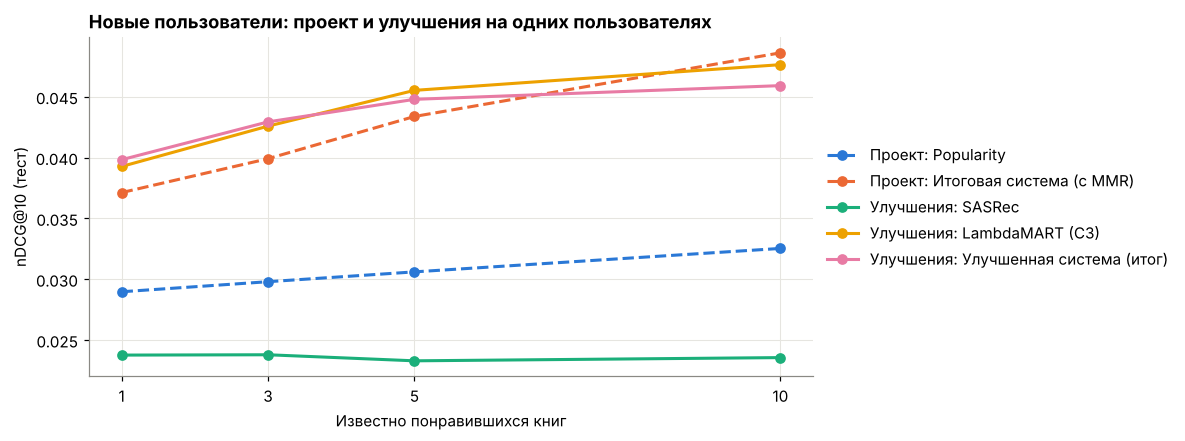

In [29]:
study.cold_start().save()
cold_ext = study.results["cold_start_ext"]
display(cold_ext.pivot(index="Модель", columns="Лайков в истории", values="nDCG@10").round(4))
plots.cold_ext(cold_ext, ["Проект: Popularity", "Проект: Итоговая система (с MMR)", "Улучшения: SASRec",
                          "Улучшения: LambdaMART (C3)", "Улучшения: Улучшенная система (итог)"], FIG);

**Новые пользователи — единственное место, где улучшения неоднозначны.** Обе системы сравнивались на одних и тех же
5 000 пользователях. При 1–5 известных лайках улучшенная система немного лучше проекта (+7% при одном лайке,
+3% при пяти), а при 10 лайках — на 6% хуже (0,046 против 0,049). SASRec сам по себе здесь даже хуже популярности,
а W&D C3 с ростом истории не растёт, а падает.

Причина в самой симуляции. У новичка оставлены **первые** лайки из train, а тест — это **последние** 20% оценок,
отделённые от них большим промежутком времени. Последовательная модель предсказывает «следующую книгу» после
ранних лайков, а она уже давно прочитана или не связана с тестом. У настоящего нового пользователя следующая книга
идёт сразу после известных, поэтому симуляция недооценивает SASRec. Практичное решение — маршрутизация: для
историй короче 10 лайков использовать ранжировщик без SASRec-признаков (C0–C2) или дать модели признак давности
последней оценки.

### 9.6. Итоговое сравнение: домашнее задание → итоговый проект → улучшения

Все числа получены на одном и том же тесте (53 303 пользователя, одинаковое разбиение по времени).
Значения ДЗ взяты из `results/metrics_summary.csv` домашнего задания; отдельные модели ДЗ воспроизводятся
в проекте до четвёртого знака.

,Этап,Система,Precision@10,Recall@10,nDCG@10,Coverage@10,"Δ nDCG@10 к Item-CF ДЗ, %"
0,Домашнее задание,Item-CF (explicit),0.0851,0.0567,0.0942,0.6554,0.0000
1,Домашнее задание,Гибрид ДЗ (CF + популярность),0.0789,0.0526,0.0875,0.4805,-7.1125
2,Итоговый проект,Гибрид (веса по сегментам),0.0910,0.0609,0.0999,0.5651,6.0534
3,Итоговый проект,GBDT-ранжировщик,0.1024,0.0698,0.1114,0.6934,18.2699
4,Итоговый проект,Wide & Deep,0.1136,0.0772,0.1287,0.4631,36.6680
5,Итоговый проект,Итоговая система (с MMR),0.1112,0.0755,0.1244,0.4972,32.0152
6,Улучшения (раздел 9),W&D C3,0.1512,0.1005,0.1771,0.6338,87.9703
7,Улучшения (раздел 9),LambdaMART (C3),0.1567,0.1045,0.1843,0.7186,95.6787
8,Улучшения (раздел 9),Улучшенная система (итог),0.1547,0.1035,0.1827,0.6999,93.9005


Весь ноутбук (разделы 1–9): 45.5 мин


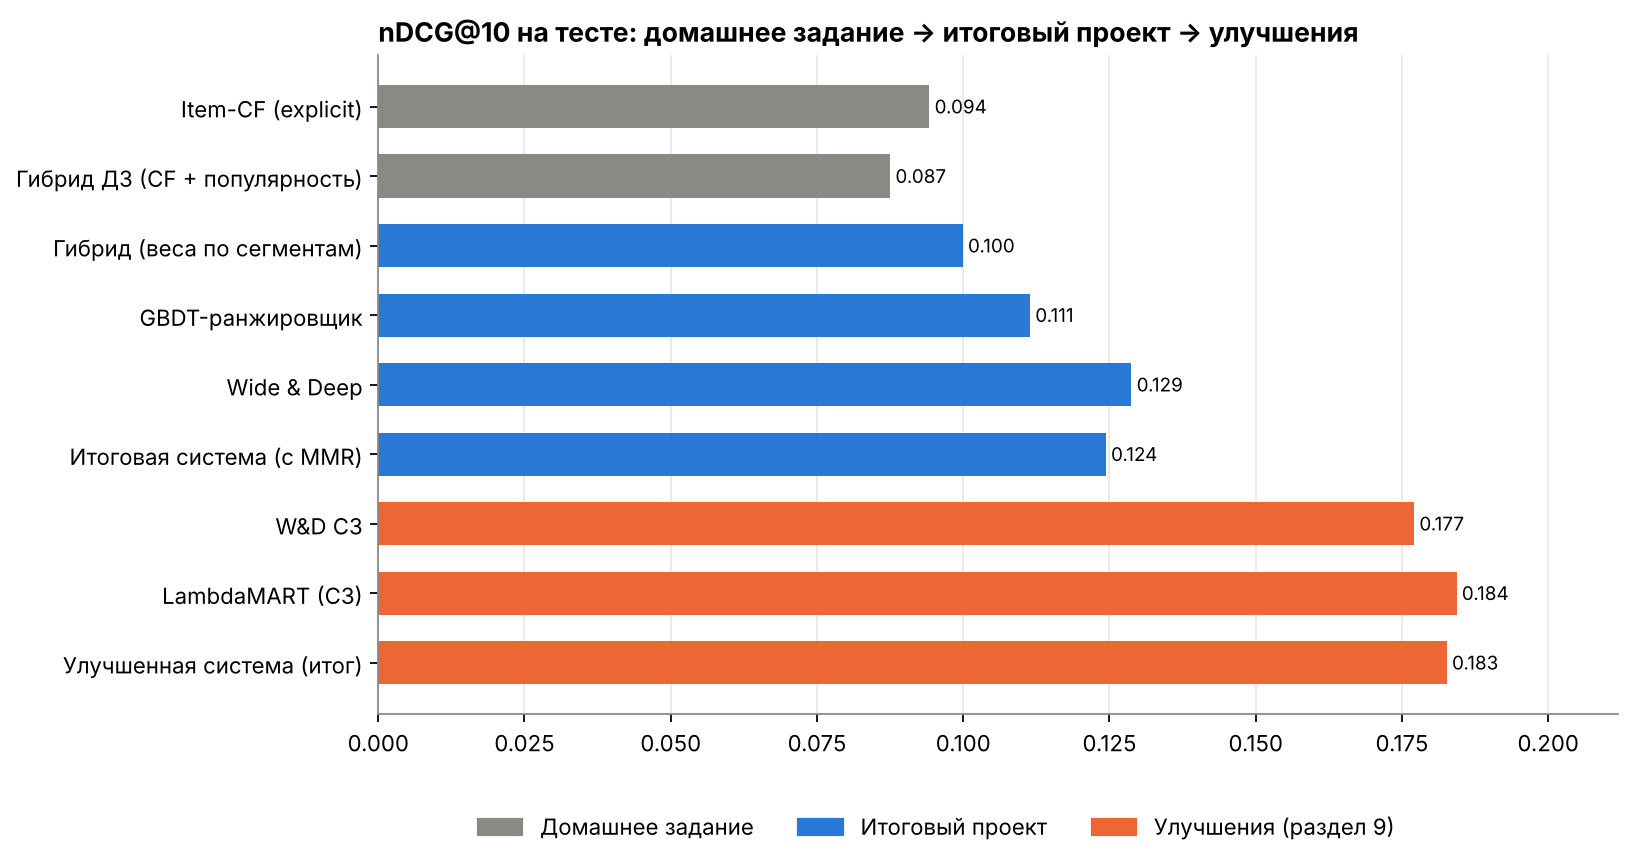

In [30]:
HW = {  # домашнее задание, results/metrics_summary.csv
    "Item-CF (explicit)": dict(P=0.0851, R=0.0567, N=0.0942, C=0.6554),
    "Гибрид ДЗ (CF + популярность)": dict(P=0.0789, R=0.0526, N=0.0875, C=0.4805),
}
proj = pipe.results["metrics_test"]
rows = [("Домашнее задание", k, v["P"], v["R"], v["N"], v["C"]) for k, v in HW.items()]
for name in ["Гибрид (веса по сегментам)", "GBDT-ранжировщик", "Wide & Deep", "Итоговая система (с MMR)"]:
    r = proj.loc[name]
    rows.append(("Итоговый проект", name, r["Precision@10"], r["Recall@10"], r["nDCG@10"], r["Coverage@10"]))
for name in ["W&D C3", "LambdaMART (C3)", "Улучшенная система (итог)"]:
    r = ext.loc[name]
    rows.append(("Улучшения (раздел 9)", name, r["Precision@10"], r["Recall@10"], r["nDCG@10"], r["Coverage@10"]))
stages = pd.DataFrame(rows, columns=["Этап", "Система", "Precision@10", "Recall@10", "nDCG@10", "Coverage@10"])
stages["Δ nDCG@10 к Item-CF ДЗ, %"] = (stages["nDCG@10"] / HW["Item-CF (explicit)"]["N"] - 1) * 100
display(stages.round(4))
stages.to_csv(cfg.results_dir / "improvements" / "stages_comparison.csv", index=False, encoding="utf-8-sig")
plots.stages(stages, FIG);
print(f"Весь ноутбук (разделы 1–9): {(time.perf_counter() - started_all) / 60:.1f} мин")

### 9.7. Выводы по исследованию улучшений

| Гипотеза | Результат | Эффект на тесте |
|---|---|---|
| H0. Порядок строк = время | **Подтверждена**: 76–79% пар частей серии идут по порядку | Открыла путь к SASRec |
| H1. EASE и RP3beta в пуле | **Подтверждена**: доля релевантных в пуле на validation 40,3% → 44,4% | nDCG@10 +5% |
| H2. Признаки серий | **Подтверждена** | nDCG@10 ещё +4% (C1 → C2) |
| H2b. Жёсткое правило порядка частей | **Отклонена** на validation | Ухудшало nDCG@10 на 1,5% |
| H3. LambdaMART вместо поточечного GBDT | **Подтверждена**: +12% к GBDT и +4% к W&D | Лучший одиночный ранжировщик: 0,184 |
| H4. Честный выбор смеси | **Подтверждена**: смесь значима на validation и лучше частей на тесте | Расхождение validation/test устранено |
| H5. SASRec как источник и признак | **Подтверждена**, крупнейший вклад | nDCG@10 +32% (C2 → C3), пул до 43,5% |

**Что улучшилось по сравнению с проектом:** nDCG@10 0,124 → 0,183 (+47%), Precision@10 0,111 → 0,155,
Recall@10 0,076 → 0,104, покрытие каталога 50% → 70%. Две слабости из диагностики — потолок пула и смещение к
популярному — заметно ослаблены, расхождение validation/test устранено.

**Что пересмотрено.** Вывод раздела 5 о том, что нейросеть лучше бустинга, верен только против поточечного GBDT.
С правильной ранжирующей функцией потерь (LambdaMART) бустинг на тех же признаках сильнее Wide & Deep, а лучший
результат даёт их смесь. Главный источник роста — не архитектура ранжировщика, а **новые сигналы**: порядок чтения
(SASRec) и структура серий.

**Что осталось и следующие шаги.**
1. Холодный старт при 5–10 лайках: маршрутизация коротких историй на ранжировщик без SASRec-признаков.
2. SASRec недообучен (4 эпохи на CPU). На локальной GPU-станции имеет смысл провести 20–50 эпох и попробовать
   gSASRec или SASRec с более длинным окном.
3. Пул всё ещё ограничивает качество (43,5%): Two-Tower с ANN-поиском (FAISS/HNSW) по эмбеддингам SASRec.
4. Исследовательские направления для защиты: LLM-переранжирование топ-20 и генеративные рекомендации (HSTU, TIGER).
   На 10 000 книг они вряд ли обгонят SASRec, но показывают современный стек.